In [1]:
%pip -q install xgboost shap

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import xgboost as xgb

from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve
)

import warnings
warnings.filterwarnings("ignore")

plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 600
plt.rcParams["font.family"] = "DejaVu Sans"

print("Libraries loaded successfully.")

Note: you may need to restart the kernel to use updated packages.
Libraries loaded successfully.


In [3]:
files = [
    "vitalsign.csv.gz",
    "triage.csv.gz",
    "edstays.csv.gz",
    "diagnosis.csv.gz",
    "patients.csv.gz",
    "admissions.csv.gz",
    "icustays.csv.gz",
    "transfers.csv.gz",
    "d_items.csv.gz"
]

for file in files:
    print("\n" + "=" * 80)
    print(file)

    df = pd.read_csv(file, compression="gzip", nrows=5, low_memory=False)

    print("COLUMNS:")
    print(df.columns.tolist())

    print("\nDATA TYPES:")
    print(df.dtypes)

    print("\nSAMPLE:")
    display(df.head(3))


vitalsign.csv.gz
COLUMNS:
['subject_id', 'stay_id', 'charttime', 'temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp', 'rhythm', 'pain']

DATA TYPES:
subject_id       int64
stay_id          int64
charttime       object
temperature    float64
heartrate      float64
resprate       float64
o2sat          float64
sbp              int64
dbp              int64
rhythm         float64
pain           float64
dtype: object

SAMPLE:


,subject_id,stay_id,charttime,temperature,heartrate,resprate,o2sat,sbp,dbp,rhythm,pain
0,10000032,32952584,2180-07-22 16:36:00,NaN,83.0,24.0,97.0,90,51,NaN,0.0
1,10000032,32952584,2180-07-22 16:43:00,NaN,85.0,22.0,98.0,76,39,NaN,0.0
2,10000032,32952584,2180-07-22 16:45:00,NaN,84.0,22.0,97.0,75,39,NaN,0.0



triage.csv.gz
COLUMNS:
['subject_id', 'stay_id', 'temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp', 'pain', 'acuity', 'chiefcomplaint']

DATA TYPES:
subject_id          int64
stay_id             int64
temperature       float64
heartrate         float64
resprate          float64
o2sat             float64
sbp               float64
dbp               float64
pain                int64
acuity            float64
chiefcomplaint     object
dtype: object

SAMPLE:


,subject_id,stay_id,temperature,heartrate,resprate,o2sat,sbp,dbp,pain,acuity,chiefcomplaint
0,10000032,32952584,97.8,87.0,14.0,97.0,71.0,43.0,7,2.0,Hypotension
1,10000032,33258284,98.4,70.0,16.0,97.0,106.0,63.0,0,3.0,"Abd pain, Abdominal distention"
2,10000032,35968195,99.4,105.0,18.0,96.0,106.0,57.0,10,3.0,"n/v/d, Abd pain"



edstays.csv.gz
COLUMNS:
['subject_id', 'hadm_id', 'stay_id', 'intime', 'outtime', 'gender', 'race', 'arrival_transport', 'disposition']

DATA TYPES:
subject_id            int64
hadm_id               int64
stay_id               int64
intime               object
outtime              object
gender               object
race                 object
arrival_transport    object
disposition          object
dtype: object

SAMPLE:


,subject_id,hadm_id,stay_id,intime,outtime,gender,race,arrival_transport,disposition
0,10000032,22595853,33258284,2180-05-06 19:17:00,2180-05-06 23:30:00,F,WHITE,AMBULANCE,ADMITTED
1,10000032,22841357,38112554,2180-06-26 15:54:00,2180-06-26 21:31:00,F,WHITE,AMBULANCE,ADMITTED
2,10000032,25742920,35968195,2180-08-05 20:58:00,2180-08-06 01:44:00,F,WHITE,AMBULANCE,ADMITTED


... (8 outputs left out)


transfers.csv.gz
COLUMNS:
['subject_id', 'hadm_id', 'transfer_id', 'eventtype', 'careunit', 'intime', 'outtime']

DATA TYPES:
subject_id      int64
hadm_id         int64
transfer_id     int64
eventtype      object
careunit       object
intime         object
outtime        object
dtype: object

SAMPLE:


,subject_id,hadm_id,transfer_id,eventtype,careunit,intime,outtime
0,10000032,22595853,33258284,ED,Emergency Department,2180-05-06 19:17:00,2180-05-06 23:30:00
1,10000032,22595853,35223874,admit,Transplant,2180-05-06 23:30:00,2180-05-07 17:21:27
2,10000032,22595853,36904543,discharge,UNKNOWN,2180-05-07 17:21:27,NaN



d_items.csv.gz
COLUMNS:
['itemid', 'label', 'abbreviation', 'linksto', 'category', 'unitname', 'param_type', 'lownormalvalue', 'highnormalvalue']

DATA TYPES:
itemid               int64
label               object
abbreviation        object
linksto             object
category            object
unitname            object
param_type          object
lownormalvalue     float64
highnormalvalue    float64
dtype: object

SAMPLE:


,itemid,label,abbreviation,linksto,category,unitname,param_type,lownormalvalue,highnormalvalue
0,220001,Problem List,Problem List,chartevents,General,NaN,Text,NaN,NaN
1,220003,ICU Admission date,ICU Admission date,datetimeevents,ADT,NaN,Date and time,NaN,NaN
2,220045,Heart Rate,HR,chartevents,Routine Vital Signs,bpm,Numeric,NaN,NaN


In [4]:
inspect_files = {
    "triage.csv.gz": [
        "chiefcomplaint", "arrival_transport", "disposition"
    ],
    "edstays.csv.gz": [
        "subject_id", "stay_id", "intime", "outtime",
        "disposition"
    ],
    "diagnosis.csv.gz": [
        "subject_id", "stay_id", "icd_code",
        "icd_version", "icd_title"
    ],
    "patients.csv.gz": [
        "subject_id", "gender", "anchor_age",
        "anchor_year", "anchor_year_group"
    ],
    "admissions.csv.gz": [
        "subject_id", "hadm_id", "admittime",
        "dischtime", "deathtime", "race"
    ],
    "vitalsign.csv.gz": [
        "subject_id", "stay_id", "charttime",
        "temperature", "heartrate", "resprate",
        "o2sat", "sbp", "dbp"
    ]
}

for file, columns in inspect_files.items():
    print("\n", "=" * 70)
    print(file)

    df = pd.read_csv(file, compression="gzip", low_memory=False)

    available = [c for c in columns if c in df.columns]

    print("Available requested columns:", available)

    for col in available:
        print(f"\n{col}:")
        print(df[col].dropna().astype(str).value_counts().head(15))


triage.csv.gz
Available requested columns: ['chiefcomplaint']

chiefcomplaint:
chiefcomplaint
Chest pain               11301
Abd pain                 10771
Dyspnea                   6003
s/p Fall                  4965
ABD PAIN                  4957
SI                        4926
ETOH                      4679
Wound eval                4509
Headache                  3828
Back pain                 3166
MVC                       3134
Altered mental status     2688
Lower back pain           2630
S/P FALL                  2579
CHEST PAIN                2577
Name: count, dtype: int64

edstays.csv.gz
Available requested columns: ['subject_id', 'stay_id', 'intime', 'outtime', 'disposition']

subject_id:
subject_id
15496609    321
16233333    210
16662316    184
14394983    170
17903094    167
10577647    156
19610016    148
15464144    139
19106010    138
14508231    136
11553072    132
16675371    127
18001923    120
18112598    115
10459551    112
Name: count, dtype: int64

stay_id:
stay_id

In [11]:
import pandas as pd
import numpy as np

df = cohort_home.copy()

df["race_group"] = np.where(
    df["race"].fillna("").str.upper().str.startswith("WHITE"),
    "White",
    "Non-white"
)

df.loc[df["race"].isna(), "race_group"] = np.nan

transport = (
    df["arrival_transport"]
    .fillna("")
    .astype(str)
    .str.upper()
    .str.strip()
)

df["arrival_group"] = np.select(
    [
        transport.eq("WALK IN"),
        transport.isin(["AMBULANCE", "HELICOPTER"])
    ],
    [
        "Walk-in",
        "Brought-in"
    ],
    default="Other/unknown"
)

categorical_variables = {
    "Sex": "gender",
    "Race": "race_group",
    "Mode of arrival": "arrival_group",
    "ED revisit within 72 hours": "ed_revisit_72h",
    "Hospital admission within 72 hours": "hospital_admission_72h",
    "ICU admission within 72 hours": "icu_admission_72h",
    "Death within 72 hours": "death_72h",
    "Serious event within 72 hours": "serious_event_72h"
}

table_rows = []

age = pd.to_numeric(df["age_at_ed"], errors="coerce").dropna()

table_rows.append({
    "Characteristic": "Age, years",
    "Category": "Mean ± SD",
    "N": len(age),
    "Percentage": np.nan,
    "Summary": f"{age.mean():.1f} ± {age.std():.1f}"
})

for variable, column in categorical_variables.items():

    values = df[column]

    
    if column.endswith("_72h"):
        values = pd.to_numeric(values, errors="coerce")
        count = int((values == 1).sum())
        denominator = int(values.notna().sum())

        table_rows.append({
            "Characteristic": variable,
            "Category": "Yes",
            "N": count,
            "Percentage": 100 * count / denominator,
            "Summary": f"{count}/{denominator} ({100*count/denominator:.2f}%)"
        })

    else:
        counts = values.value_counts(dropna=False)

        for category, count in counts.items():
            denominator = int(values.notna().sum())

            table_rows.append({
                "Characteristic": variable,
                "Category": str(category),
                "N": int(count),
                "Percentage": (
                    100 * count / denominator
                    if pd.notna(category) else np.nan
                ),
                "Summary": (
                    f"{count}/{denominator} "
                    f"({100*count/denominator:.2f}%)"
                    if pd.notna(category) else f"{count} missing"
                )
            })

characteristics_table = pd.DataFrame(table_rows)

print("TABLE 1. PATIENT CHARACTERISTICS AND THREE-DAY OUTCOMES")
print("=" * 75)
display(characteristics_table)

# Save publication table
characteristics_table.to_csv(
    "Table_1_Patient_Characteristics_and_72h_Outcomes.csv",
    index=False
)

print("\nSaved: Table_1_Patient_Characteristics_and_72h_Outcomes.csv")

TABLE 1. PATIENT CHARACTERISTICS AND THREE-DAY OUTCOMES


,Characteristic,Category,N,Percentage,Summary
0,"Age, years",Mean ± SD,11723,NaN,44.4 ± 17.9
1,Sex,F,8403,71.679604,8403/11723 (71.68%)
2,Sex,M,3320,28.320396,3320/11723 (28.32%)
3,Race,Non-white,6324,53.945236,6324/11723 (53.95%)
4,Race,White,5399,46.054764,5399/11723 (46.05%)
5,Mode of arrival,Walk-in,9320,79.501834,9320/11723 (79.50%)
6,Mode of arrival,Brought-in,2351,20.054594,2351/11723 (20.05%)
7,Mode of arrival,Other/unknown,52,0.443572,52/11723 (0.44%)
8,ED revisit within 72 hours,Yes,520,4.435725,520/11723 (4.44%)
9,Hospital admission within 72 hours,Yes,202,1.723108,202/11723 (1.72%)



Saved: Table_1_Patient_Characteristics_and_72h_Outcomes.csv


In [10]:
for df, columns in [
    (edstays, ["intime", "outtime"]),
    (admissions, ["admittime", "deathtime"]),
    (icustays, ["intime"])
]:
    for col in columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")


base = cohort_home[
    ["stay_id", "subject_id",
     "index_discharge_date", "followup_end_date"]
].copy()

def calculate_event_flag(base_df, event_df, event_date_col,
                         output_name, exclude_index_stay=False):

    events = event_df.copy()
    events[event_date_col] = pd.to_datetime(
        events[event_date_col], errors="coerce"
    ).dt.normalize()

    merged = base_df.merge(
        events,
        on="subject_id",
        how="left"
    )

    valid = (
        merged[event_date_col].notna() &
        (merged[event_date_col] > merged["index_discharge_date"]) &
        (merged[event_date_col] <= merged["followup_end_date"])
    )

    if exclude_index_stay:
        valid &= merged["event_stay_id"] != merged["stay_id"]

    flags = (
        merged.assign(event=valid.astype(int))
        .groupby("stay_id")["event"]
        .max()
    )

    return flags.reindex(base_df["stay_id"]).fillna(0).astype(int).to_numpy()


ed_events = edstays[
    ["subject_id", "stay_id", "intime"]
].rename(columns={
    "stay_id": "event_stay_id",
    "intime": "event_date"
})

cohort_home["ed_revisit_72h"] = calculate_event_flag(
    base, ed_events, "event_date",
    "ed_revisit_72h", exclude_index_stay=True
)

admission_events = admissions[
    ["subject_id", "admittime"]
].rename(columns={"admittime": "event_date"})

cohort_home["hospital_admission_72h"] = calculate_event_flag(
    base, admission_events, "event_date",
    "hospital_admission_72h"
)

icu_events = icustays[
    ["subject_id", "intime"]
].rename(columns={"intime": "event_date"})

cohort_home["icu_admission_72h"] = calculate_event_flag(
    base, icu_events, "event_date",
    "icu_admission_72h"
)

death_from_admissions = admissions.loc[
    admissions["deathtime"].notna(),
    ["subject_id", "deathtime"]
].rename(columns={"deathtime": "death_date"})

patients_death = patients.copy()
patients_death["dod"] = pd.to_datetime(
    patients_death["dod"], errors="coerce"
)

death_from_patients = patients_death.loc[
    patients_death["dod"].notna(),
    ["subject_id", "dod"]
].rename(columns={"dod": "death_date"})

death_events = pd.concat(
    [death_from_admissions, death_from_patients],
    ignore_index=True
)

death_events["death_date"] = pd.to_datetime(
    death_events["death_date"], errors="coerce"
).dt.normalize()

death_events = (
    death_events.groupby("subject_id", as_index=False)
    ["death_date"].min()
)

cohort_home["death_72h"] = calculate_event_flag(
    base, death_events, "death_date", "death_72h"
)

cohort_home["serious_event_72h"] = (
    (
        cohort_home["hospital_admission_72h"].eq(1) |
        cohort_home["icu_admission_72h"].eq(1) |
        cohort_home["death_72h"].eq(1)
    ).astype(int)
)

outcome_columns = [
    "ed_revisit_72h",
    "hospital_admission_72h",
    "icu_admission_72h",
    "death_72h",
    "serious_event_72h"
]

outcome_summary = pd.DataFrame({
    "Outcome": outcome_columns,
    "Events": [
        cohort_home[col].sum() for col in outcome_columns
    ],
    "Percentage": [
        cohort_home[col].mean() * 100 for col in outcome_columns
    ]
})

outcome_summary["Percentage"] = (
    outcome_summary["Percentage"].round(2)
)

print("THREE-DAY OUTCOME SUMMARY")
print("=" * 60)
display(outcome_summary)

print("\nOutcome overlap:")
display(
    cohort_home[outcome_columns].value_counts()
    .reset_index(name="Number of encounters")
)

outcome_summary.to_csv(
    DATA_DIR / "Table_72h_Outcomes.csv",
    index=False
)

cohort_home.to_csv(
    DATA_DIR / "Headache_Home_Discharge_Cohort.csv",
    index=False
)

print("\nSaved outcome table and cohort dataset.")

THREE-DAY OUTCOME SUMMARY


,Outcome,Events,Percentage
0,ed_revisit_72h,520,4.44
1,hospital_admission_72h,202,1.72
2,icu_admission_72h,13,0.11
3,death_72h,1,0.01
4,serious_event_72h,204,1.74



Outcome overlap:


,ed_revisit_72h,hospital_admission_72h,icu_admission_72h,death_72h,serious_event_72h,Number of encounters
0,0,0,0,0,0,11170
1,1,0,0,0,0,349
2,1,1,0,0,1,160
3,0,1,0,0,1,30
4,1,1,1,0,1,11
5,0,0,0,1,1,1
6,0,0,1,0,1,1
7,0,1,1,0,1,1



Saved outcome table and cohort dataset.


In [9]:
edstays["intime"] = pd.to_datetime(edstays["intime"], errors="coerce")
edstays["outtime"] = pd.to_datetime(edstays["outtime"], errors="coerce")

complaint_mask = (
    triage["chiefcomplaint"]
    .fillna("")
    .astype(str)
    .str.contains("headache", case=False, na=False)
)

complaint_stays = set(
    triage.loc[complaint_mask, "stay_id"].dropna()
)

diagnosis_copy = diagnosis.copy()

diagnosis_copy["icd_code"] = (
    diagnosis_copy["icd_code"].astype(str).str.upper().str.replace(".", "", regex=False)
)

diagnosis_copy["icd_version"] = pd.to_numeric(
    diagnosis_copy["icd_version"], errors="coerce"
)

diagnosis_mask = (
    (diagnosis_copy["icd_version"] == 10) &
    (
        diagnosis_copy["icd_code"].str.startswith("R51", na=False) |
        diagnosis_copy["icd_code"].str.startswith("G43", na=False)
    )
)

diagnosis_stays = set(
    diagnosis_copy.loc[diagnosis_mask, "stay_id"].dropna()
)

headache_stays = complaint_stays.union(diagnosis_stays)


cohort = edstays[
    edstays["stay_id"].isin(headache_stays)
].copy()


patient_columns = [
    "subject_id", "anchor_age", "anchor_year", "gender"
]

cohort = cohort.merge(
    patients[patient_columns].drop_duplicates("subject_id"),
    on="subject_id",
    how="left",
    suffixes=("", "_patient")
)


cohort["age_at_ed"] = (
    cohort["anchor_age"] +
    cohort["intime"].dt.year -
    cohort["anchor_year"]
)


cohort_adults = cohort[
    cohort["age_at_ed"] >= 18
].copy()


cohort_home = cohort_adults[
    cohort_adults["disposition"].astype(str).str.upper().str.strip()
    == "HOME"
].copy()


triage_predictors = [
    "stay_id", "temperature", "heartrate",
    "resprate", "o2sat", "sbp", "pain"
]

cohort_home = cohort_home.merge(
    triage[triage_predictors].drop_duplicates("stay_id"),
    on="stay_id",
    how="left",
    validate="one_to_one"
)


cohort_home["index_discharge_date"] = (
    cohort_home["outtime"].dt.normalize()
)

cohort_home["followup_end_date"] = (
    cohort_home["index_discharge_date"] +
    pd.Timedelta(days=3)
)


print("HEADACHE COHORT FLOW")
print("=" * 60)
print("Unique ED stays with headache complaint:",
      len(complaint_stays))
print("Unique ED stays with ICD-10 R51/G43:",
      len(diagnosis_stays))
print("Combined headache ED stays:",
      len(headache_stays))
print("Combined cohort records:", len(cohort))
print("Adult headache ED stays:", len(cohort_adults))
print("Adult HOME discharges:", len(cohort_home))
print("Unique patients in home-discharge cohort:",
      cohort_home["subject_id"].nunique())

print("\nED disposition in adult headache cohort:")
display(cohort_adults["disposition"].value_counts(dropna=False))

print("\nArrival transport categories:")
display(cohort_home["arrival_transport"].value_counts(dropna=False))

print("\nSex distribution:")
display(cohort_home["gender"].value_counts(dropna=False))

print("\nRace distribution:")
display(cohort_home["race"].value_counts(dropna=False))

print("\nIndex discharge date missing:",
      cohort_home["index_discharge_date"].isna().sum())

print("\nTriage predictor missingness:")
display(
    cohort_home[
        ["temperature", "heartrate", "resprate",
         "o2sat", "sbp", "pain"]
    ].isna().sum()
)

HEADACHE COHORT FLOW
Unique ED stays with headache complaint: 13814
Unique ED stays with ICD-10 R51/G43: 7596
Combined headache ED stays: 15927
Combined cohort records: 15927
Adult headache ED stays: 15915
Adult HOME discharges: 11723
Unique patients in home-discharge cohort: 9699

ED disposition in adult headache cohort:


disposition
HOME                           11723
ADMITTED                        3265
LEFT WITHOUT BEING SEEN          395
ELOPED                           248
TRANSFER                         126
LEFT AGAINST MEDICAL ADVICE      112
OTHER                             42
EXPIRED                            4
Name: count, dtype: int64


Arrival transport categories:


arrival_transport
WALK IN       9320
AMBULANCE     2350
UNKNOWN         32
OTHER           20
HELICOPTER       1
Name: count, dtype: int64


Sex distribution:


gender
F    8403
M    3320
Name: count, dtype: int64


Race distribution:


race
WHITE                                        4900
BLACK/AFRICAN AMERICAN                       2567
OTHER                                         771
HISPANIC/LATINO - PUERTO RICAN                594
HISPANIC/LATINO - DOMINICAN                   495
BLACK/CAPE VERDEAN                            435
WHITE - OTHER EUROPEAN                        250
ASIAN                                         224
BLACK/AFRICAN                                 220
ASIAN - CHINESE                               186
WHITE - RUSSIAN                               152
BLACK/CARIBBEAN ISLAND                        152
HISPANIC/LATINO - GUATEMALAN                  118
SOUTH AMERICAN                                 60
HISPANIC/LATINO - COLUMBIAN                    60
HISPANIC/LATINO - SALVADORAN                   59
WHITE - BRAZILIAN                              55
HISPANIC/LATINO - MEXICAN                      44
HISPANIC/LATINO - CENTRAL AMERICAN             44
WHITE - EASTERN EUROPEAN                     


Index discharge date missing: 0

Triage predictor missingness:


temperature    182
heartrate       65
resprate       111
o2sat          129
sbp             96
pain            42
dtype: int64

In [8]:
import numpy as np

triage_analysis = triage.copy()

numeric_columns = [
    "temperature", "heartrate", "resprate",
    "o2sat", "sbp", "pain"
]

for col in numeric_columns:
    triage_analysis[col] = pd.to_numeric(
        triage_analysis[col], errors="coerce"
    )


triage_analysis["temperature_status"] = np.select(
    [triage_analysis["temperature"] < 97,
     triage_analysis["temperature"] > 99],
    ["Below range", "Above range"],
    default="Within range"
)

triage_analysis["heart_rate_status"] = np.select(
    [triage_analysis["heartrate"] < 60,
     triage_analysis["heartrate"] > 100],
    ["Below range", "Above range"],
    default="Within range"
)

triage_analysis["respiratory_rate_status"] = np.select(
    [triage_analysis["resprate"] < 12,
     triage_analysis["resprate"] > 20],
    ["Below range", "Above range"],
    default="Within range"
)

triage_analysis["oxygen_saturation_status"] = np.select(
    [triage_analysis["o2sat"] < 94,
     triage_analysis["o2sat"] > 100],
    ["Below range", "Above range"],
    default="Within range"
)

triage_analysis["sbp_status"] = np.select(
    [triage_analysis["sbp"] < 90,
     triage_analysis["sbp"] > 119],
    ["Below range", "Above range"],
    default="Within range"
)

triage_analysis["pain_category"] = pd.cut(
    triage_analysis["pain"],
    bins=[-0.01, 0, 3, 6, 10],
    labels=["No pain", "Mild", "Moderate", "Severe"]
)


print("Triage records:", len(triage_analysis))
print("Unique ED stays:", triage_analysis["stay_id"].nunique())
print("Duplicate stay IDs:",
      triage_analysis["stay_id"].duplicated().sum())

print("\nMissing predictor values:")
display(triage_analysis[numeric_columns].isna().sum())

print("\nPain score distribution:")
display(triage_analysis["pain_category"].value_counts(
    dropna=False
))

Triage records: 425087
Unique ED stays: 425087
Duplicate stay IDs: 0

Missing predictor values:


temperature    23415
heartrate      17090
resprate       20353
o2sat          20596
sbp            18291
pain           28114
dtype: int64


Pain score distribution:


pain_category
No pain     140811
Severe      134733
Moderate     74201
NaN          39318
Mild         36024
Name: count, dtype: int64

In [7]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("/Users/dereckkaale")

triage = pd.read_csv(DATA_DIR / "triage.csv.gz")
edstays = pd.read_csv(DATA_DIR / "edstays.csv.gz")
patients = pd.read_csv(DATA_DIR / "patients.csv.gz")
admissions = pd.read_csv(DATA_DIR / "admissions.csv.gz")
icustays = pd.read_csv(DATA_DIR / "icustays.csv.gz")
diagnosis = pd.read_csv(DATA_DIR / "diagnosis.csv.gz")

print("DATASETS LOADED SUCCESSFULLY")
print("=" * 50)

for name, df in {
    "triage": triage,
    "edstays": edstays,
    "patients": patients,
    "admissions": admissions,
    "icustays": icustays,
    "diagnosis": diagnosis
}.items():
    print(f"{name}: {df.shape}")

DATASETS LOADED SUCCESSFULLY
triage: (425087, 11)
edstays: (425087, 9)
patients: (364627, 6)
admissions: (546028, 16)
icustays: (94458, 8)
diagnosis: (899050, 6)


In [12]:
import numpy as np
import pandas as pd
import sklearn
import xgboost
import shap

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    brier_score_loss, confusion_matrix,
    accuracy_score, precision_score, recall_score,
    f1_score
)

print("Package versions")
print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("SHAP:", shap.__version__)

numeric_features = [
    "age_at_ed", "heartrate", "sbp",
    "o2sat", "resprate", "temperature", "pain"
]

categorical_features = ["gender"]

feature_columns = numeric_features + categorical_features

model_data = df[
    ["subject_id", "serious_event_72h"] + feature_columns
].copy()

for col in numeric_features:
    model_data[col] = pd.to_numeric(
        model_data[col], errors="coerce"
    )

model_data["gender"] = model_data["gender"].astype("category")

model_data = model_data.dropna(
    subset=["subject_id", "serious_event_72h"]
).copy()

model_data["serious_event_72h"] = (
    model_data["serious_event_72h"].astype(int)
)

X = model_data[feature_columns]
y = model_data["serious_event_72h"]
groups = model_data["subject_id"]

print("\nMODELLING DATASET")
print("=" * 60)
print("Encounters:", len(model_data))
print("Unique patients:", groups.nunique())
print("Serious events:", int(y.sum()))
print("Event prevalence:", round(y.mean() * 100, 2), "%")
print("\nMissing predictors:")
display(X.isna().sum())


splitter = StratifiedGroupKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

train_patients = set(groups.iloc[train_idx])
test_patients = set(groups.iloc[test_idx])

print("\nPATIENT-LEVEL TRAIN-TEST SPLIT")
print("=" * 60)
print("Training encounters:", len(X_train))
print("Test encounters:", len(X_test))
print("Training patients:", len(train_patients))
print("Test patients:", len(test_patients))
print("Patient overlap:", len(train_patients & test_patients))

print("\nTraining events:", int(y_train.sum()))
print("Training prevalence:", round(y_train.mean() * 100, 2), "%")
print("Test events:", int(y_test.sum()))
print("Test prevalence:", round(y_test.mean() * 100, 2), "%")


train_ids = model_data.iloc[train_idx][
    ["subject_id"]
].copy()
train_ids["split"] = "Training"

test_ids = model_data.iloc[test_idx][
    ["subject_id"]
].copy()
test_ids["split"] = "Test"

split_records = pd.concat(
    [train_ids, test_ids],
    ignore_index=True
)

split_records.to_csv(
    "Patient_Level_Train_Test_Split.csv",
    index=False
)

Package versions
scikit-learn: 1.7.2
XGBoost: 3.2.0
SHAP: 0.51.0

MODELLING DATASET
Encounters: 11723
Unique patients: 9699
Serious events: 204
Event prevalence: 1.74 %

Missing predictors:


age_at_ed        0
heartrate       65
sbp             96
o2sat          129
resprate       111
temperature    182
pain           227
gender           0
dtype: int64


PATIENT-LEVEL TRAIN-TEST SPLIT
Training encounters: 10526
Test encounters: 1197
Training patients: 8732
Test patients: 967
Patient overlap: 0

Training events: 188
Training prevalence: 1.79 %
Test events: 16
Test prevalence: 1.34 %


In [13]:
numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

scale_pos_weight = (
    (y_train == 0).sum() / (y_train == 1).sum()
)

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=500,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=2,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

fitted_models = {}
performance = []
test_predictions = {}

for name, classifier in models.items():

    print("Training:", name)

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    probabilities = pipeline.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    performance.append({
        "Model": name,
        "AUROC": roc_auc_score(y_test, probabilities),
        "AUPRC": average_precision_score(y_test, probabilities),
        "Brier score": brier_score_loss(y_test, probabilities),
        "Sensitivity": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "F1 score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

    fitted_models[name] = pipeline
    test_predictions[name] = probabilities

performance_table = pd.DataFrame(performance)

print("\nHELD-OUT TEST PERFORMANCE")
print("=" * 80)
display(performance_table.round(4))

performance_table.to_csv(
    "Table_2_Model_Performance.csv",
    index=False
)

print("\nSaved: Table_2_Model_Performance.csv")

Training: Logistic Regression
Training: Random Forest
Training: XGBoost

HELD-OUT TEST PERFORMANCE


,Model,AUROC,AUPRC,Brier score,Sensitivity,Specificity,Precision,F1 score
0,Logistic Regression,0.5752,0.0170,0.2409,0.500,0.5792,0.0158,0.0307
1,Random Forest,0.6494,0.0234,0.0188,0.000,1.0000,0.0000,0.0000
2,XGBoost,0.5554,0.0258,0.1463,0.375,0.8230,0.0279,0.0519



Saved: Table_2_Model_Performance.csv


In [14]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    brier_score_loss, confusion_matrix,
    recall_score, precision_score, f1_score
)

splitter = StratifiedGroupKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

folds = list(splitter.split(X, y, groups=groups))


test_idx = np.concatenate([folds[i][1] for i in range(3)])
train_idx = np.concatenate([folds[i][1] for i in range(3, 10)])

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

print("CORRECTED PATIENT-LEVEL SPLIT")
print("=" * 60)
print("Training encounters:", len(X_train))
print("Test encounters:", len(X_test))
print("Training patients:", groups_train.nunique())
print("Test patients:", groups_test.nunique())
print("Patient overlap:",
      len(set(groups_train) & set(groups_test)))

print("\nTraining events:", int(y_train.sum()))
print("Training prevalence:", round(y_train.mean() * 100, 2), "%")
print("Test events:", int(y_test.sum()))
print("Test prevalence:", round(y_test.mean() * 100, 2), "%")

scale_pos_weight = (
    (y_train == 0).sum() / (y_train == 1).sum()
)

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=500,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=2,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

fitted_models = {}
performance = []
test_predictions = {}

for name, classifier in models.items():

    print("\nTraining:", name)

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    probabilities = pipeline.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    performance.append({
        "Model": name,
        "AUROC": roc_auc_score(y_test, probabilities),
        "AUPRC": average_precision_score(y_test, probabilities),
        "Brier score": brier_score_loss(y_test, probabilities),
        "Sensitivity": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "F1 score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

    fitted_models[name] = pipeline
    test_predictions[name] = probabilities

performance_table = pd.DataFrame(performance)

print("\nCORRECTED HELD-OUT TEST PERFORMANCE")
print("=" * 80)
display(performance_table.round(4))

performance_table.to_csv(
    "Table_2_Model_Performance_70_30.csv",
    index=False
)

split_records = pd.DataFrame({
    "subject_id": groups.to_numpy(),
    "split": np.where(
        np.isin(np.arange(len(groups)), train_idx),
        "Training",
        "Test"
    )
})

split_records.to_csv(
    "Patient_Level_Train_Test_Split_70_30.csv",
    index=False
)

print("\nSaved corrected model performance and split files.")

CORRECTED PATIENT-LEVEL SPLIT
Training encounters: 8222
Test encounters: 3501
Training patients: 6793
Test patients: 2906
Patient overlap: 0

Training events: 152
Training prevalence: 1.85 %
Test events: 52
Test prevalence: 1.49 %

Training: Logistic Regression

Training: Random Forest

Training: XGBoost

CORRECTED HELD-OUT TEST PERFORMANCE


,Model,AUROC,AUPRC,Brier score,Sensitivity,Specificity,Precision,F1 score
0,Logistic Regression,0.5622,0.0196,0.2327,0.4423,0.6184,0.0172,0.0331
1,Random Forest,0.5682,0.0204,0.0202,0.0000,0.9997,0.0000,0.0000
2,XGBoost,0.5494,0.0183,0.1296,0.1731,0.8562,0.0178,0.0323



Saved corrected model performance and split files.


In [15]:
import pandas as pd

print("COHORT DATAFRAME")
print("Shape:", df.shape)

outcome_cols = [
    "outtime",
    "index_discharge_date",
    "followup_end",
    "ed_revisit_72h",
    "hospital_admission_72h",
    "icu_admission_72h",
    "death_72h",
    "serious_event_72h"
]

print("\nAvailable outcome-related columns:")
print([c for c in outcome_cols if c in df.columns])

date_checks = {
    "edstays": ["intime", "outtime"],
    "admissions": ["admittime", "dischtime", "deathtime"],
    "icustays": ["intime", "outtime"]
}

datasets = {
    "edstays": edstays,
    "admissions": admissions,
    "icustays": icustays
}

for name, columns in date_checks.items():
    data = datasets[name]
    print(f"\n{name.upper()} DATE CHECK")
    for col in columns:
        if col in data.columns:
            values = pd.to_datetime(data[col], errors="coerce")
            print(
                f"{col}: valid={values.notna().sum():,}, "
                f"missing={values.isna().sum():,}, "
                f"earliest={values.min()}, latest={values.max()}"
            )

print("\nINDEX COHORT DATE VARIABLES")
for col in ["outtime", "index_discharge_date", "followup_end"]:
    if col in df.columns:
        values = pd.to_datetime(df[col], errors="coerce")
        print(
            f"{col}: valid={values.notna().sum():,}, "
            f"missing={values.isna().sum():,}, "
            f"earliest={values.min()}, latest={values.max()}"
        )

print("\n72-HOUR OUTCOME AUDIT")
for col in [
    "ed_revisit_72h",
    "hospital_admission_72h",
    "icu_admission_72h",
    "death_72h",
    "serious_event_72h"
]:
    if col in df.columns:
        print(f"\n{col}")
        print(df[col].value_counts(dropna=False))

components = [
    "hospital_admission_72h",
    "icu_admission_72h",
    "death_72h"
]

if all(c in df.columns for c in components) and "serious_event_72h" in df.columns:
    expected = (
        df[components].fillna(0).astype(int).max(axis=1)
    )
    actual = df["serious_event_72h"].fillna(0).astype(int)

    print("\nCOMPOSITE OUTCOME CONSISTENCY")
    print("Mismatched records:", (expected != actual).sum())
    print("Expected serious events:", expected.sum())
    print("Recorded serious events:", actual.sum())


COHORT DATAFRAME
Shape: (11723, 28)

Available outcome-related columns:
['outtime', 'index_discharge_date', 'ed_revisit_72h', 'hospital_admission_72h', 'icu_admission_72h', 'death_72h', 'serious_event_72h']

EDSTAYS DATE CHECK
intime: valid=425,087, missing=0, earliest=2110-01-11 01:45:00, latest=2212-04-05 23:23:00
outtime: valid=425,087, missing=0, earliest=2110-01-11 07:04:00, latest=2212-04-06 14:20:00

ADMISSIONS DATE CHECK
admittime: valid=546,028, missing=0, earliest=2105-10-04 17:26:00, latest=2214-12-15 19:11:00
dischtime: valid=546,028, missing=0, earliest=2105-10-12 11:11:00, latest=2214-12-24 13:44:00
deathtime: valid=11,790, missing=534,238, earliest=2110-01-25 09:40:00, latest=2214-10-12 12:51:00

ICUSTAYS DATE CHECK
intime: valid=94,458, missing=0, earliest=2110-01-11 10:16:06, latest=2214-07-22 17:05:53
outtime: valid=94,444, missing=14, earliest=2110-01-12 17:17:47, latest=2214-07-26 17:13:57

INDEX COHORT DATE VARIABLES
outtime: valid=11,723, missing=0, earliest=2110-

In [18]:
import pandas as pd
import numpy as np

index = df[["subject_id", "stay_id", "outtime"]].copy().reset_index(drop=True)

index["outtime"] = pd.to_datetime(index["outtime"], errors="coerce")
index["window_end"] = index["outtime"] + pd.Timedelta(hours=72)


ed = edstays[["subject_id", "stay_id", "intime"]].copy()
ed["intime"] = pd.to_datetime(ed["intime"], errors="coerce")

adm = admissions[["subject_id", "admittime", "deathtime"]].copy()
adm["admittime"] = pd.to_datetime(adm["admittime"], errors="coerce")
adm["deathtime"] = pd.to_datetime(adm["deathtime"], errors="coerce")

icu = icustays[["subject_id", "intime"]].copy()
icu["intime"] = pd.to_datetime(icu["intime"], errors="coerce")


def check_event(index_data, event_data, event_time, exclude_same_stay=False):

    event_lookup = {}

    for subject_id, group in event_data.groupby("subject_id"):
        event_lookup[subject_id] = group

    results = []

    for row in index_data.itertuples():

        patient_events = event_lookup.get(row.subject_id)

        if patient_events is None:
            results.append(0)
            continue

        times = patient_events[event_time]

        valid = (
            times.notna()
            & (times > row.outtime)
            & (times <= row.window_end)
        )

        if exclude_same_stay:
            valid &= patient_events["stay_id"] != row.stay_id

        results.append(int(valid.any()))

    return pd.Series(results, index=index_data.index)


index["ed_revisit_exact"] = check_event(
    index, ed, "intime", exclude_same_stay=True
)

index["hospital_admission_exact"] = check_event(
    index, adm, "admittime"
)

index["icu_admission_exact"] = check_event(
    index, icu, "intime"
)

index["death_exact"] = check_event(
    index, adm, "deathtime"
)

index["serious_event_exact"] = index[
    [
        "hospital_admission_exact",
        "icu_admission_exact",
        "death_exact"
    ]
].max(axis=1)


comparisons = {
    "ed_revisit_72h": "ed_revisit_exact",
    "hospital_admission_72h": "hospital_admission_exact",
    "icu_admission_72h": "icu_admission_exact",
    "death_72h": "death_exact",
    "serious_event_72h": "serious_event_exact"
}

print("EXACT 72-HOUR OUTCOME COMPARISON")
print("=" * 65)

for old, new in comparisons.items():

    existing = df[old].fillna(0).astype(int).reset_index(drop=True)
    recalculated = index[new].reset_index(drop=True)

    print(f"\n{old}")
    print("Existing events:", existing.sum())
    print("Exact 72-hour events:", recalculated.sum())
    print("Mismatches:", (existing != recalculated).sum())

    print(
        "Existing positive, exact negative:",
        ((existing == 1) & (recalculated == 0)).sum()
    )

    print(
        "Existing negative, exact positive:",
        ((existing == 0) & (recalculated == 1)).sum()
    )

print("\nRECALCULATED COMPOSITE")
print(index["serious_event_exact"].value_counts())
print(
    "Prevalence:",
    round(index["serious_event_exact"].mean() * 100, 3),
    "%"
)


EXACT 72-HOUR OUTCOME COMPARISON

ed_revisit_72h
Existing events: 520
Exact 72-hour events: 539
Mismatches: 131
Existing positive, exact negative: 56
Existing negative, exact positive: 75

hospital_admission_72h
Existing events: 202
Exact 72-hour events: 210
Mismatches: 58
Existing positive, exact negative: 25
Existing negative, exact positive: 33

icu_admission_72h
Existing events: 13
Exact 72-hour events: 14
Mismatches: 1
Existing positive, exact negative: 0
Existing negative, exact positive: 1

death_72h
Existing events: 1
Exact 72-hour events: 0
Mismatches: 1
Existing positive, exact negative: 1
Existing negative, exact positive: 0

serious_event_72h
Existing events: 204
Exact 72-hour events: 211
Mismatches: 59
Existing positive, exact negative: 26
Existing negative, exact positive: 33

RECALCULATED COMPOSITE
serious_event_exact
0    11512
1      211
Name: count, dtype: int64
Prevalence: 1.8 %


In [19]:
checks = {
    "ED revisit": ("ed_revisit_72h", "ed_revisit_exact"),
    "Hospital admission": ("hospital_admission_72h", "hospital_admission_exact"),
    "ICU admission": ("icu_admission_72h", "icu_admission_exact"),
    "Death": ("death_72h", "death_exact"),
    "Composite": ("serious_event_72h", "serious_event_exact")
}

for label, (old, new) in checks.items():
    mismatch = (
        df[old].fillna(0).astype(int).reset_index(drop=True)
        != index[new].reset_index(drop=True)
    )

    print(f"\n{label.upper()} — MISMATCHES: {mismatch.sum()}")

    if mismatch.sum() == 0:
        continue

    rows = df.loc[mismatch].copy()
    rows["exact_outcome"] = index.loc[mismatch, new].values

    display_cols = [
        "subject_id", "stay_id", "outtime",
        "index_discharge_date", old, "exact_outcome"
    ]

    if "hadm_id" in rows.columns:
        display_cols.insert(2, "hadm_id")

    print(rows[display_cols].head(10).to_string(index=False))


print("\nDEATH RECORD INVESTIGATION")
death_rows = df[df["death_72h"].fillna(0).astype(int) == 1]

if len(death_rows) == 0:
    print("No original death-positive record found.")
else:
    for row in death_rows.itertuples():
        print("\nIndex encounter:")
        print("Patient:", row.subject_id)
        print("Stay:", row.stay_id)
        print("Discharge:", row.outtime)
        print("Discharge date:", row.index_discharge_date)

        patient_deaths = admissions[
            (admissions["subject_id"] == row.subject_id)
            & admissions["deathtime"].notna()
        ][["subject_id", "hadm_id", "admittime", "deathtime"]]

        print("Patient death records:")
        print(patient_deaths.to_string(index=False))


print("\nHOSPITAL ADMISSION EVENT INVESTIGATION")

positive_ids = index.loc[
    index["hospital_admission_exact"] == 1,
    ["subject_id", "stay_id", "outtime", "window_end"]
].head(10)

for row in positive_ids.itertuples():
    print(
        f"\nPatient {row.subject_id} | Stay {row.stay_id} "
        f"| Discharged {row.outtime}"
    )

    events = admissions[
        (admissions["subject_id"] == row.subject_id)
        & admissions["admittime"].notna()
    ][["hadm_id", "admittime", "dischtime"]].copy()

    events["hours_after_discharge"] = (
        pd.to_datetime(events["admittime"]) - row.outtime
    ).dt.total_seconds() / 3600

    print(
        events[
            (events["hours_after_discharge"] > 0)
            & (events["hours_after_discharge"] <= 168)
        ].to_string(index=False)
    )



ED REVISIT — MISMATCHES: 131
 subject_id  stay_id    hadm_id             outtime index_discharge_date  ed_revisit_72h  exact_outcome
   10027100 38142904        NaN 2158-03-08 05:09:00           2158-03-08               0              1
   10161042 36713848 22070504.0 2178-04-20 14:33:00           2178-04-20               0              1
   10180796 33883739        NaN 2181-11-21 17:45:00           2181-11-21               0              1
   10229306 39179783        NaN 2124-12-22 16:26:00           2124-12-22               0              1
   10365942 39055152        NaN 2114-08-02 07:38:00           2114-08-02               1              0
   10427304 32549933        NaN 2141-02-03 01:56:00           2141-02-03               0              1
   10459551 37849440        NaN 2159-02-10 04:13:00           2159-02-10               1              0
   10460305 36691482        NaN 2188-02-27 06:49:00           2188-02-27               0              1
   10529115 33224345        NaN 21

In [20]:
admissions_check = admissions.copy()
admissions_check["admittime"] = pd.to_datetime(
    admissions_check["admittime"], errors="coerce"
)

patients_check = patients.copy()
patients_check["dod"] = pd.to_datetime(
    patients_check["dod"], errors="coerce"
)

old = df["hospital_admission_72h"].fillna(0).astype(int).reset_index(drop=True)
new = index["hospital_admission_exact"].reset_index(drop=True)

mismatch_positions = np.where(old != new)[0]

print("HOSPITAL ADMISSION MISMATCH DETAILS")
print("=" * 75)

for pos in mismatch_positions:

    row = df.iloc[pos]
    discharge = pd.to_datetime(row["outtime"])
    end_time = discharge + pd.Timedelta(hours=72)

    print(
        f"\nPatient: {row['subject_id']} | "
        f"Stay: {row['stay_id']} | "
        f"Index hadm_id: {row['hadm_id']}"
    )

    print("Discharge:", discharge)
    print("Original outcome:", old.iloc[pos])
    print("Exact outcome:", new.iloc[pos])

    events = admissions_check[
        admissions_check["subject_id"] == row["subject_id"]
    ][["hadm_id", "admittime", "dischtime"]].copy()

    events["hours_from_discharge"] = (
        events["admittime"] - discharge
    ).dt.total_seconds() / 3600

    events = events[
        events["admittime"].notna()
        & (events["admittime"] >= discharge - pd.Timedelta(hours=24))
        & (events["admittime"] <= discharge + pd.Timedelta(days=4))
    ].copy()

    events["same_index_hadm"] = (
        events["hadm_id"] == row["hadm_id"]
    )

    print(events.to_string(index=False))


print("\n\nDEATH RECORD VERIFICATION")
print("=" * 75)

death_rows = df[
    df["death_72h"].fillna(0).astype(int) == 1
]

for row in death_rows.itertuples():

    print("\nPatient:", row.subject_id)
    print("Index stay:", row.stay_id)
    print("Index discharge:", row.outtime)

    patient_record = patients_check[
        patients_check["subject_id"] == row.subject_id
    ][["subject_id", "dod"]]

    print("Patient date of death:")
    print(patient_record.to_string(index=False))

    admission_records = admissions_check[
        admissions_check["subject_id"] == row.subject_id
    ][["hadm_id", "admittime", "dischtime", "deathtime"]]

    print("Admission records:")
    print(admission_records.to_string(index=False))

print("\n\nINDEX ENCOUNTER LINKAGE")
print("=" * 75)

print("Cohort encounters:", len(df))
print("With index hadm_id:", df["hadm_id"].notna().sum())
print("Without index hadm_id:", df["hadm_id"].isna().sum())

print(
    "Index hadm_id found in admissions:",
    df["hadm_id"].dropna().isin(admissions["hadm_id"]).sum()
)


HOSPITAL ADMISSION MISMATCH DETAILS

Patient: 10161042 | Stay: 36713848 | Index hadm_id: 22070504.0
Discharge: 2178-04-20 14:33:00
Original outcome: 0
Exact outcome: 1
 hadm_id           admittime           dischtime  hours_from_discharge  same_index_hadm
22070504 2178-04-20 02:25:00 2178-04-20 14:33:00            -12.133333             True
27215540 2178-04-20 17:40:00 2178-04-25 13:44:00              3.116667            False

Patient: 10325255 | Stay: 30393361 | Index hadm_id: 24449325.0
Discharge: 2152-01-01 20:06:00
Original outcome: 0
Exact outcome: 1
 hadm_id           admittime           dischtime  hours_from_discharge  same_index_hadm
24449325 2152-01-01 20:45:00 2152-01-03 15:24:00                  0.65             True

Patient: 10462684 | Stay: 37890627 | Index hadm_id: 27066656.0
Discharge: 2131-08-21 07:51:00
Original outcome: 0
Exact outcome: 1
 hadm_id           admittime           dischtime  hours_from_discharge  same_index_hadm
20449187 2131-08-21 15:58:00 2131-08-28 

In [21]:
import pandas as pd
import numpy as np

idx = df[
    ["subject_id", "stay_id", "hadm_id", "outtime"]
].copy().reset_index(drop=True)

idx["outtime"] = pd.to_datetime(idx["outtime"], errors="coerce")
idx["window_end"] = idx["outtime"] + pd.Timedelta(hours=72)

adm = admissions[
    ["subject_id", "hadm_id", "admittime", "dischtime"]
].copy()

adm["admittime"] = pd.to_datetime(adm["admittime"], errors="coerce")

icu = icustays[
    ["subject_id", "hadm_id", "intime"]
].copy()

icu["intime"] = pd.to_datetime(icu["intime"], errors="coerce")

print("INDEX ADMISSION LINKAGE")
print("=" * 65)

print("Total cohort encounters:", len(idx))
print("With index hadm_id:", idx["hadm_id"].notna().sum())
print("Without index hadm_id:", idx["hadm_id"].isna().sum())

merged = idx.merge(
    adm,
    on="subject_id",
    how="left",
    suffixes=("_index", "_event")
)

merged["hours_after_discharge"] = (
    merged["admittime"] - merged["outtime"]
).dt.total_seconds() / 3600

within = merged[
    (merged["hours_after_discharge"] > 0)
    & (merged["hours_after_discharge"] <= 72)
].copy()

within["same_index_hadm"] = (
    within["hadm_id_index"].notna()
    & (
        within["hadm_id_index"].astype("Int64")
        == within["hadm_id_event"].astype("Int64")
    )
)

print("\nADMISSIONS WITHIN EXACT 72 HOURS")
print("Total linked admission records:", len(within))
print("Same index hadm_id:", within["same_index_hadm"].sum())
print("Different hadm_id:", (~within["same_index_hadm"]).sum())

print("\nUnique index encounters with qualifying admissions:")
print(within["stay_id"].nunique())

print("\nUnique index encounters with same index hadm_id:")
print(
    within.loc[within["same_index_hadm"], "stay_id"].nunique()
)

print("\nUnique index encounters with different hadm_id:")
print(
    within.loc[~within["same_index_hadm"], "stay_id"].nunique()
)

print("\nINDEX HADMI_ID LINKAGE DETAILS")

linked = idx[idx["hadm_id"].notna()].copy()

print("Index encounters with hadm_id:", len(linked))

print("\nTheir original outcome:")
print(
    df.loc[linked.index, "serious_event_72h"]
    .value_counts(dropna=False)
)

icu_merged = idx.merge(
    icu,
    on="subject_id",
    how="left",
    suffixes=("_index", "_icu")
)

icu_merged["hours_after_discharge"] = (
    icu_merged["intime"] - icu_merged["outtime"]
).dt.total_seconds() / 3600

icu_within = icu_merged[
    (icu_merged["hours_after_discharge"] > 0)
    & (icu_merged["hours_after_discharge"] <= 72)
].copy()

icu_within["same_index_hadm"] = (
    icu_within["hadm_id_index"].notna()
    & (
        icu_within["hadm_id_index"].astype("Int64")
        == icu_within["hadm_id_icu"].astype("Int64")
    )
)

print("\nICU LINKAGE")
print("Qualifying ICU records:", len(icu_within))
print("Same index hadm_id:", icu_within["same_index_hadm"].sum())
print("Different hadm_id:", (~icu_within["same_index_hadm"]).sum())

death_data = patients[["subject_id", "dod"]].copy()
death_data["dod"] = pd.to_datetime(
    death_data["dod"], errors="coerce"
)

death_idx = idx.merge(
    death_data,
    on="subject_id",
    how="left"
)

death_idx["days_after_discharge"] = (
    death_idx["dod"].dt.normalize()
    - death_idx["outtime"].dt.normalize()
).dt.days

death_within = death_idx[
    (death_idx["days_after_discharge"] >= 0)
    & (death_idx["days_after_discharge"] <= 3)
].copy()

print("\nDEATH DATE AUDIT")
print("Deaths recorded in patients.dod:", death_data["dod"].notna().sum())
print("Cohort patients with recorded death date:",
      death_idx["dod"].notna().sum())
print("Deaths on discharge date through 3 calendar days:",
      len(death_within))

print("\nDeath records requiring review:")
print(
    death_within[
        [
            "subject_id", "stay_id", "outtime",
            "dod", "days_after_discharge"
        ]
    ].to_string(index=False)
)


INDEX ADMISSION LINKAGE
Total cohort encounters: 11723
With index hadm_id: 682
Without index hadm_id: 11041

ADMISSIONS WITHIN EXACT 72 HOURS
Total linked admission records: 214
Same index hadm_id: 14
Different hadm_id: 200

Unique index encounters with qualifying admissions:
210

Unique index encounters with same index hadm_id:
14

Unique index encounters with different hadm_id:
196

INDEX HADMI_ID LINKAGE DETAILS
Index encounters with hadm_id: 682

Their original outcome:
serious_event_72h
0    662
1     20
Name: count, dtype: int64

ICU LINKAGE
Qualifying ICU records: 14
Same index hadm_id: 2
Different hadm_id: 12

DEATH DATE AUDIT
Deaths recorded in patients.dod: 38301
Cohort patients with recorded death date: 501
Deaths on discharge date through 3 calendar days: 1

Death records requiring review:
 subject_id  stay_id             outtime        dod  days_after_discharge
   18287213 33352951 2140-02-08 05:25:00 2140-02-10                   2.0


In [22]:
import pandas as pd
import numpy as np

idx = df[["subject_id", "stay_id", "hadm_id", "outtime"]].copy()
idx = idx.reset_index(drop=True)

idx["outtime"] = pd.to_datetime(idx["outtime"], errors="coerce")
idx["window_end"] = idx["outtime"] + pd.Timedelta(hours=72)
idx["index_row"] = idx.index

idx["index_hadm_id"] = pd.to_numeric(
    idx["hadm_id"], errors="coerce"
)


ed = edstays[["subject_id", "stay_id", "intime"]].copy()
ed["intime"] = pd.to_datetime(ed["intime"], errors="coerce")

ed_events = idx.merge(
    ed,
    on="subject_id",
    how="left",
    suffixes=("_index", "_event")
)

ed_events["ed_revisit"] = (
    ed_events["stay_id_event"].notna()
    & (ed_events["stay_id_event"] != ed_events["stay_id_index"])
    & (ed_events["intime"] > ed_events["outtime"])
    & (ed_events["intime"] <= ed_events["window_end"])
)

ed_flags = (
    ed_events.groupby("index_row")["ed_revisit"]
    .any()
    .astype(int)
)


adm = admissions[["subject_id", "hadm_id", "admittime"]].copy()
adm["admittime"] = pd.to_datetime(adm["admittime"], errors="coerce")
adm["event_hadm_id"] = pd.to_numeric(adm["hadm_id"], errors="coerce")

adm_events = idx.merge(
    adm,
    on="subject_id",
    how="left"
)

adm_events["different_hadm"] = (
    adm_events["event_hadm_id"].notna()
    & (
        adm_events["index_hadm_id"].isna()
        | (adm_events["event_hadm_id"] != adm_events["index_hadm_id"])
    )
)

adm_events["hospital_admission"] = (
    adm_events["different_hadm"]
    & (adm_events["admittime"] > adm_events["outtime"])
    & (adm_events["admittime"] <= adm_events["window_end"])
)

adm_flags = (
    adm_events.groupby("index_row")["hospital_admission"]
    .any()
    .astype(int)
)


icu = icustays[["subject_id", "hadm_id", "intime"]].copy()
icu["intime"] = pd.to_datetime(icu["intime"], errors="coerce")
icu["event_hadm_id"] = pd.to_numeric(icu["hadm_id"], errors="coerce")

icu_events = idx.merge(
    icu,
    on="subject_id",
    how="left"
)

icu_events["different_hadm"] = (
    icu_events["event_hadm_id"].notna()
    & (
        icu_events["index_hadm_id"].isna()
        | (icu_events["event_hadm_id"] != icu_events["index_hadm_id"])
    )
)

icu_events["icu_admission"] = (
    icu_events["different_hadm"]
    & (icu_events["intime"] > icu_events["outtime"])
    & (icu_events["intime"] <= icu_events["window_end"])
)

icu_flags = (
    icu_events.groupby("index_row")["icu_admission"]
    .any()
    .astype(int)
)


death_events = admissions[
    ["subject_id", "deathtime"]
].copy()

death_events["deathtime"] = pd.to_datetime(
    death_events["deathtime"], errors="coerce"
)

death_events = idx.merge(
    death_events,
    on="subject_id",
    how="left"
)

death_events["exact_death"] = (
    (death_events["deathtime"] > death_events["outtime"])
    & (death_events["deathtime"] <= death_events["window_end"])
)

exact_death_flags = (
    death_events.groupby("index_row")["exact_death"]
    .any()
    .astype(int)
)

dod = patients[["subject_id", "dod"]].copy()
dod["dod"] = pd.to_datetime(dod["dod"], errors="coerce")

death_date = idx.merge(dod, on="subject_id", how="left")

death_date["days_after_discharge"] = (
    death_date["dod"].dt.normalize()
    - death_date["outtime"].dt.normalize()
).dt.days


death_date["date_only_death"] = (
    death_date["days_after_discharge"].between(1, 2)
)

date_death_flags = (
    death_date.groupby("index_row")["date_only_death"]
    .any()
    .astype(int)
)

death_flags = (
    exact_death_flags.combine(date_death_flags, max)
)


df_corrected = df.copy().reset_index(drop=True)

df_corrected["ed_revisit_72h"] = (
    ed_flags.reindex(df_corrected.index, fill_value=0).values
)

df_corrected["hospital_admission_72h"] = (
    adm_flags.reindex(df_corrected.index, fill_value=0).values
)

df_corrected["icu_admission_72h"] = (
    icu_flags.reindex(df_corrected.index, fill_value=0).values
)

df_corrected["death_72h"] = (
    death_flags.reindex(df_corrected.index, fill_value=0).values
)

df_corrected["serious_event_72h"] = (
    df_corrected[
        [
            "hospital_admission_72h",
            "icu_admission_72h",
            "death_72h"
        ]
    ].max(axis=1)
)


outcome_columns = [
    "ed_revisit_72h",
    "hospital_admission_72h",
    "icu_admission_72h",
    "death_72h",
    "serious_event_72h"
]

print("CORRECTED EXACT 72-HOUR OUTCOMES")
print("=" * 65)

for col in outcome_columns:
    count = int(df_corrected[col].sum())
    percentage = count / len(df_corrected) * 100

    print(
        f"{col:<28} {count:>6,} "
        f"({percentage:>5.2f}%)"
    )

print("\nCOMPOSITE OUTCOME CONSISTENCY")
expected = df_corrected[
    ["hospital_admission_72h", "icu_admission_72h", "death_72h"]
].max(axis=1)

print(
    "Mismatches:",
    int((expected != df_corrected["serious_event_72h"]).sum())
)

print("\nCorrected dataframe shape:", df_corrected.shape)

CORRECTED EXACT 72-HOUR OUTCOMES
ed_revisit_72h                  539 ( 4.60%)
hospital_admission_72h          196 ( 1.67%)
icu_admission_72h                12 ( 0.10%)
death_72h                         1 ( 0.01%)
serious_event_72h               197 ( 1.68%)

COMPOSITE OUTCOME CONSISTENCY
Mismatches: 0

Corrected dataframe shape: (11723, 28)


In [23]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold


numeric_features = [
    "age_at_ed",
    "heartrate",
    "sbp",
    "o2sat",
    "resprate",
    "temperature",
    "pain"
]

categorical_features = ["gender"]

target = "serious_event_72h"

required_columns = (
    numeric_features
    + categorical_features
    + [target, "subject_id"]
)

missing_columns = [
    col for col in required_columns
    if col not in df_corrected.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

model_data = df_corrected[required_columns].copy()

for col in numeric_features:
    model_data[col] = pd.to_numeric(
        model_data[col], errors="coerce"
    )

model_data[target] = model_data[target].astype(int)

model_data = model_data.dropna(
    subset=["subject_id", target]
).reset_index(drop=True)


print("UPDATED MODELLING DATASET")
print("=" * 55)
print("Encounters:", len(model_data))
print("Unique patients:", model_data["subject_id"].nunique())
print("Serious events:", model_data[target].sum())
print(
    "Event prevalence:",
    round(model_data[target].mean() * 100, 2), "%"
)


cv = StratifiedGroupKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

folds = list(
    cv.split(
        model_data,
        model_data[target],
        groups=model_data["subject_id"]
    )
)

test_indices = np.concatenate([
    folds[i][1] for i in range(3)
])

train_indices = np.concatenate([
    folds[i][1] for i in range(3, 10)
])

X = model_data[numeric_features + categorical_features]
y = model_data[target]
groups = model_data["subject_id"]

X_train = X.iloc[train_indices].copy()
X_test = X.iloc[test_indices].copy()

y_train = y.iloc[train_indices].copy()
y_test = y.iloc[test_indices].copy()

groups_train = groups.iloc[train_indices]
groups_test = groups.iloc[test_indices]


overlap = set(groups_train).intersection(set(groups_test))

print("\nPATIENT-LEVEL TRAIN–TEST SPLIT")
print("=" * 55)

print("Training encounters:", len(X_train))
print("Test encounters:", len(X_test))

print("Training patients:", groups_train.nunique())
print("Test patients:", groups_test.nunique())

print("\nTRAINING OUTCOME")
print("Events:", int(y_train.sum()))
print("Prevalence:", round(y_train.mean() * 100, 2), "%")

print("\nTEST OUTCOME")
print("Events:", int(y_test.sum()))
print("Prevalence:", round(y_test.mean() * 100, 2), "%")

print("\nPatient overlap:", len(overlap))

UPDATED MODELLING DATASET
Encounters: 11723
Unique patients: 9699
Serious events: 197
Event prevalence: 1.68 %

PATIENT-LEVEL TRAIN–TEST SPLIT
Training encounters: 8161
Test encounters: 3562
Training patients: 6790
Test patients: 2909

TRAINING OUTCOME
Events: 143
Prevalence: 1.75 %

TEST OUTCOME
Events: 54
Prevalence: 1.52 %

Patient overlap: 0


In [24]:
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

from xgboost import XGBClassifier


numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])


scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=500,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=2,
        scale_pos_weight=scale_pos_weight,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}


results = []
predictions = {}

for name, classifier in models.items():

    print(f"Training {name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    probabilities = pipeline.predict_proba(X_test)[:, 1]
    predicted = (probabilities >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predicted, labels=[0, 1]
    ).ravel()

    results.append({
        "Model": name,
        "AUROC": roc_auc_score(y_test, probabilities),
        "AUPRC": average_precision_score(y_test, probabilities),
        "Brier score": brier_score_loss(y_test, probabilities),
        "Sensitivity": recall_score(
            y_test, predicted, zero_division=0
        ),
        "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "Precision": precision_score(
            y_test, predicted, zero_division=0
        ),
        "F1 score": f1_score(
            y_test, predicted, zero_division=0
        ),
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn
    })

    predictions[name] = probabilities

    
    models[name] = pipeline


performance = pd.DataFrame(results)

print("\nCORRECTED OUTCOME — TEST SET PERFORMANCE")
print("=" * 85)

display(
    performance.round(4)
)

performance.to_csv(
    "Corrected_72h_Model_Performance.csv",
    index=False
)

prediction_data = pd.DataFrame({
    "subject_id": groups_test.values,
    "actual_outcome": y_test.values,
    **predictions
})

prediction_data.to_csv(
    "Corrected_72h_Model_Predictions.csv",
    index=False
)

print("\nSaved:")
print("1. Corrected_72h_Model_Performance.csv")
print("2. Corrected_72h_Model_Predictions.csv")

Training Logistic Regression...
Training Random Forest...
Training XGBoost...

CORRECTED OUTCOME — TEST SET PERFORMANCE


,Model,AUROC,AUPRC,Brier score,Sensitivity,Specificity,Precision,F1 score,TP,FP,TN,FN
0,Logistic Regression,0.5940,0.0289,0.2390,0.5556,0.6072,0.0213,0.0410,30,1378,2130,24
1,Random Forest,0.5357,0.0287,0.0201,0.0000,1.0000,0.0000,0.0000,0,0,3508,54
2,XGBoost,0.5070,0.0207,0.1336,0.1852,0.8398,0.0175,0.0319,10,562,2946,44



Saved:
1. Corrected_72h_Model_Performance.csv
2. Corrected_72h_Model_Predictions.csv


In [25]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.01, 0.02, 0.05, 0.10, 0.20, 0.50]

threshold_results = []
probability_summary = []

for name, prob in predictions.items():

    prob = np.asarray(prob)

    probability_summary.append({
        "Model": name,
        "Minimum": prob.min(),
        "25th percentile": np.percentile(prob, 25),
        "Median": np.median(prob),
        "75th percentile": np.percentile(prob, 75),
        "95th percentile": np.percentile(prob, 95),
        "99th percentile": np.percentile(prob, 99),
        "Maximum": prob.max()
    })

    for threshold in thresholds:

        predicted = (prob >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_test, predicted, labels=[0, 1]
        ).ravel()

        threshold_results.append({
            "Model": name,
            "Threshold": threshold,
            "Predicted positives": int(predicted.sum()),
            "TP": tp,
            "FP": fp,
            "TN": tn,
            "FN": fn,
            "Sensitivity": recall_score(
                y_test, predicted, zero_division=0
            ),
            "Specificity": tn / (tn + fp),
            "Precision": precision_score(
                y_test, predicted, zero_division=0
            ),
            "F1 score": f1_score(
                y_test, predicted, zero_division=0
            )
        })

probability_summary = pd.DataFrame(probability_summary)
threshold_results = pd.DataFrame(threshold_results)

print("PREDICTED PROBABILITY DISTRIBUTIONS")
display(probability_summary.round(4))

print("\nTHRESHOLD DIAGNOSTICS")
display(threshold_results.round(4))

probability_summary.to_csv(
    "Corrected_Model_Probability_Distributions.csv",
    index=False
)

threshold_results.to_csv(
    "Corrected_Model_Threshold_Diagnostics.csv",
    index=False
)

PREDICTED PROBABILITY DISTRIBUTIONS


,Model,Minimum,25th percentile,Median,75th percentile,95th percentile,99th percentile,Maximum
0,Logistic Regression,0.2019,0.4035,0.4729,0.5443,0.6643,0.7387,0.9972
1,Random Forest,0.0000,0.0286,0.0518,0.0882,0.1781,0.2557,0.4458
2,XGBoost,0.0051,0.1756,0.2893,0.4323,0.6297,0.7592,0.8613



THRESHOLD DIAGNOSTICS


,Model,Threshold,Predicted positives,TP,FP,TN,FN,Sensitivity,Specificity,Precision,F1 score
0,Logistic Regression,0.01,3562,54,3508,0,0,1.0000,0.0000,0.0152,0.0299
1,Logistic Regression,0.02,3562,54,3508,0,0,1.0000,0.0000,0.0152,0.0299
2,Logistic Regression,0.05,3562,54,3508,0,0,1.0000,0.0000,0.0152,0.0299
3,Logistic Regression,0.10,3562,54,3508,0,0,1.0000,0.0000,0.0152,0.0299
4,Logistic Regression,0.20,3562,54,3508,0,0,1.0000,0.0000,0.0152,0.0299
5,Logistic Regression,0.50,1408,30,1378,2130,24,0.5556,0.6072,0.0213,0.0410
6,Random Forest,0.01,3404,54,3350,158,0,1.0000,0.0450,0.0159,0.0312
7,Random Forest,0.02,3034,47,2987,521,7,0.8704,0.1485,0.0155,0.0304
8,Random Forest,0.05,1845,28,1817,1691,26,0.5185,0.4820,0.0152,0.0295
9,Random Forest,0.10,716,14,702,2806,40,0.2593,0.7999,0.0196,0.0364


In [26]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

y_array = np.asarray(y_test)
patient_array = np.asarray(groups_test)

model_names = [
    "Logistic Regression",
    "Random Forest",
    "XGBoost"
]

unique_patients = np.unique(patient_array)

patient_indices = {
    patient: np.where(patient_array == patient)[0]
    for patient in unique_patients
}

N_BOOTSTRAPS = 2000
RANDOM_STATE = 42

rng = np.random.default_rng(RANDOM_STATE)

bootstrap_results = {
    name: {"AUROC": [], "AUPRC": []}
    for name in model_names
}

valid_bootstraps = 0

for b in range(N_BOOTSTRAPS):

    sampled_patients = rng.choice(
        unique_patients,
        size=len(unique_patients),
        replace=True
    )

    
    sampled_indices = np.concatenate([
        patient_indices[p]
        for p in sampled_patients
    ])

    y_boot = y_array[sampled_indices]

    if len(np.unique(y_boot)) < 2:
        continue

    valid_bootstraps += 1

    for name in model_names:

        prob_boot = np.asarray(
            predictions[name]
        )[sampled_indices]

        auc_value = roc_auc_score(
            y_boot, prob_boot
        )

        ap_value = average_precision_score(
            y_boot, prob_boot
        )

        bootstrap_results[name]["AUROC"].append(
            auc_value
        )

        bootstrap_results[name]["AUPRC"].append(
            ap_value
        )

summary = []

for name in model_names:

    auc_values = np.array(
        bootstrap_results[name]["AUROC"]
    )

    ap_values = np.array(
        bootstrap_results[name]["AUPRC"]
    )

    summary.append({
        "Model": name,

        "AUROC": roc_auc_score(
            y_array, predictions[name]
        ),

        "AUROC 95% CI lower": np.percentile(
            auc_values, 2.5
        ),

        "AUROC 95% CI upper": np.percentile(
            auc_values, 97.5
        ),

        "AUPRC": average_precision_score(
            y_array, predictions[name]
        ),

        "AUPRC 95% CI lower": np.percentile(
            ap_values, 2.5
        ),

        "AUPRC 95% CI upper": np.percentile(
            ap_values, 97.5
        )
    })

ci_results = pd.DataFrame(summary)

print("PATIENT-LEVEL BOOTSTRAP RESULTS")
print("=" * 75)

print("Requested bootstrap samples:", N_BOOTSTRAPS)
print("Valid bootstrap samples:", valid_bootstraps)

display(ci_results.round(4))

ci_results.to_csv(
    "Corrected_Model_Performance_95CI.csv",
    index=False
)

print("\nSaved: Corrected_Model_Performance_95CI.csv")

PATIENT-LEVEL BOOTSTRAP RESULTS
Requested bootstrap samples: 2000
Valid bootstrap samples: 2000


,Model,AUROC,AUROC 95% CI lower,AUROC 95% CI upper,AUPRC,AUPRC 95% CI lower,AUPRC 95% CI upper
0,Logistic Regression,0.5940,0.5048,0.6712,0.0289,0.0152,0.0764
1,Random Forest,0.5357,0.4481,0.6228,0.0287,0.0140,0.0790
2,XGBoost,0.5070,0.4210,0.5931,0.0207,0.0123,0.0479



Saved: Corrected_Model_Performance_95CI.csv


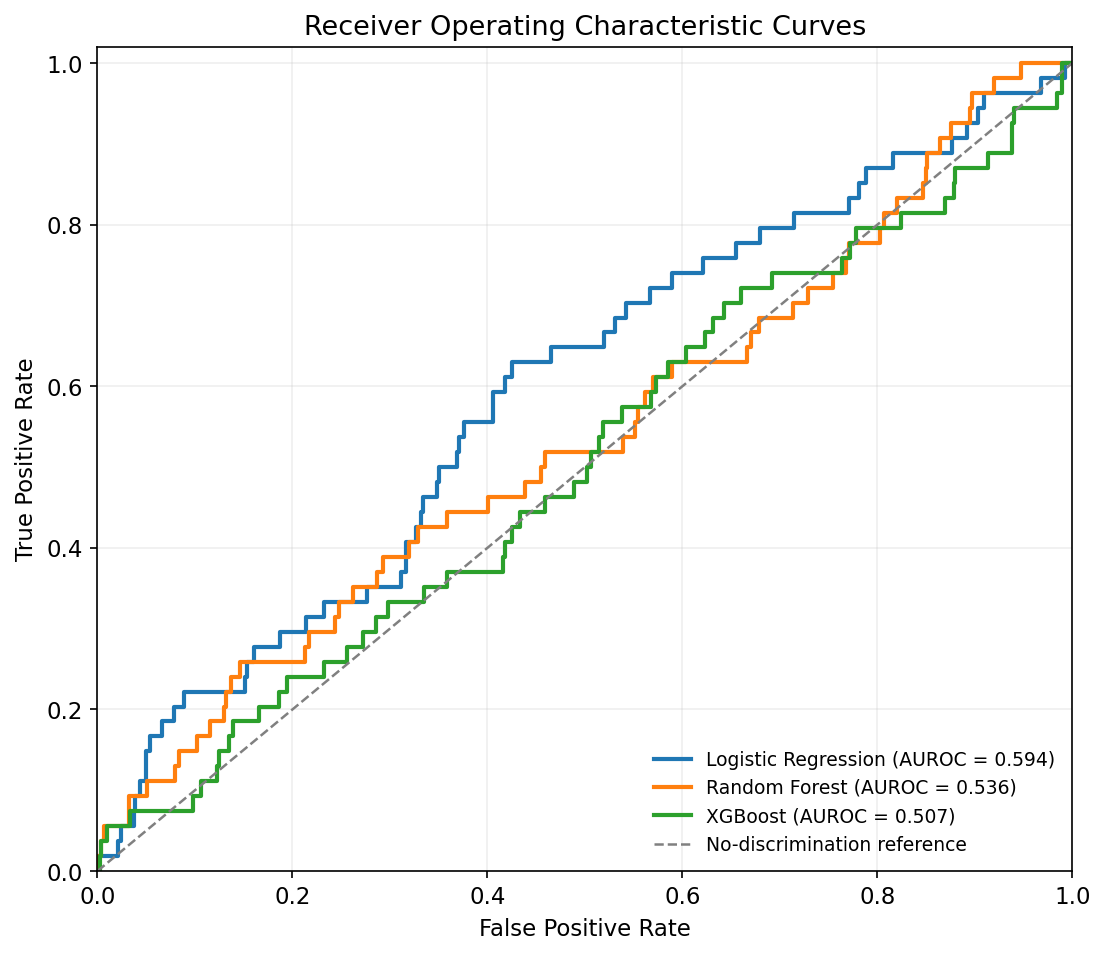

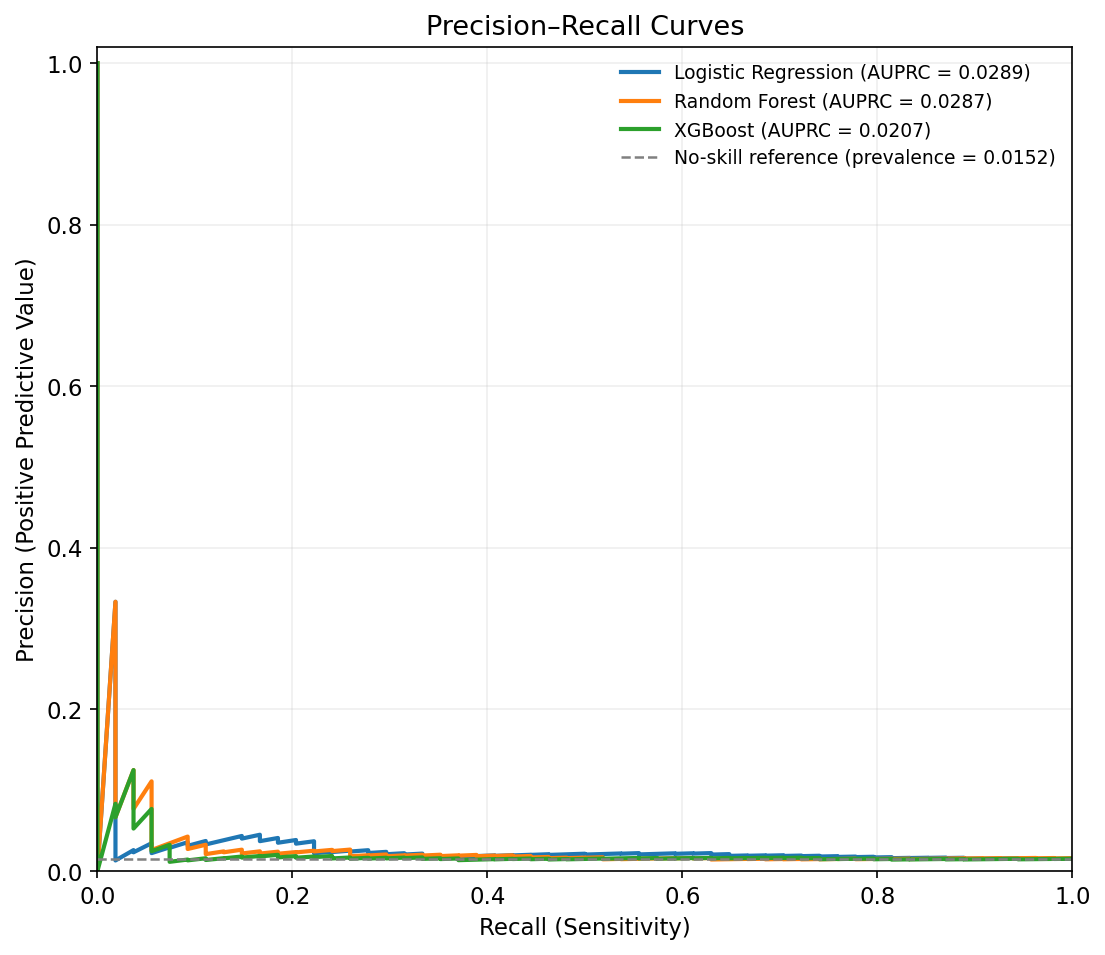

FOUR FIGURE FILES SAVED:
1. Figure_ROC_Three_Models.png
2. Figure_ROC_Three_Models.pdf
3. Figure_PR_Three_Models.png
4. Figure_PR_Three_Models.pdf


In [27]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

model_names = [
    "Logistic Regression",
    "Random Forest",
    "XGBoost"
]

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 9
})

fig, ax = plt.subplots(figsize=(7.5, 6.5))

for name in model_names:

    prob = predictions[name]

    fpr, tpr, _ = roc_curve(y_test, prob)
    roc_auc = auc(fpr, tpr)

    ax.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUROC = {roc_auc:.3f})"
    )

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    linewidth=1.2,
    color="grey",
    label="No-discrimination reference"
)

ax.set_title("Receiver Operating Characteristic Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right", frameon=False)
ax.grid(alpha=0.2)

fig.tight_layout()

fig.savefig(
    "Figure_ROC_Three_Models.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    "Figure_ROC_Three_Models.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


fig, ax = plt.subplots(figsize=(7.5, 6.5))

for name in model_names:

    prob = predictions[name]

    precision, recall, _ = precision_recall_curve(
        y_test, prob
    )

    ap = average_precision_score(y_test, prob)

    ax.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{name} (AUPRC = {ap:.4f})"
    )

prevalence = y_test.mean()

ax.axhline(
    prevalence,
    linestyle="--",
    linewidth=1.2,
    color="grey",
    label=f"No-skill reference (prevalence = {prevalence:.4f})"
)

ax.set_title("Precision–Recall Curves")
ax.set_xlabel("Recall (Sensitivity)")
ax.set_ylabel("Precision (Positive Predictive Value)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="upper right", frameon=False)
ax.grid(alpha=0.2)

fig.tight_layout()

fig.savefig(
    "Figure_PR_Three_Models.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    "Figure_PR_Three_Models.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("FOUR FIGURE FILES SAVED:")
print("1. Figure_ROC_Three_Models.png")
print("2. Figure_ROC_Three_Models.pdf")
print("3. Figure_PR_Three_Models.png")
print("4. Figure_PR_Three_Models.pdf")


Patient-grouped calibration folds verified.
Calibrating Logistic Regression...
Calibrating Random Forest...
Calibrating XGBoost...

CALIBRATION PERFORMANCE


,Model,Probability type,AUROC,AUPRC,Brier score,Log loss,Calibration-in-the-large,Calibration intercept,Calibration slope,Mean predicted risk,Observed prevalence
0,Logistic Regression,Original,0.5940,0.0289,0.2390,0.6735,-4.2200,-4.1708,0.6367,0.4781,0.0152
1,Logistic Regression,Calibrated,0.5973,0.0294,0.0148,0.0775,-0.1672,0.1842,1.0890,0.0179,0.0152
2,Random Forest,Original,0.5357,0.0287,0.0201,0.1132,-1.5787,-3.5541,0.2152,0.0668,0.0152
3,Random Forest,Calibrated,0.5382,0.0243,0.0149,0.0784,-0.1410,0.3313,1.1176,0.0174,0.0152
4,XGBoost,Original,0.5070,0.0207,0.1336,0.4283,-3.6351,-4.1613,0.0131,0.3122,0.0152
5,XGBoost,Calibrated,0.4810,0.0157,0.0149,0.0789,-0.1454,-6.1029,-0.4776,0.0175,0.0152


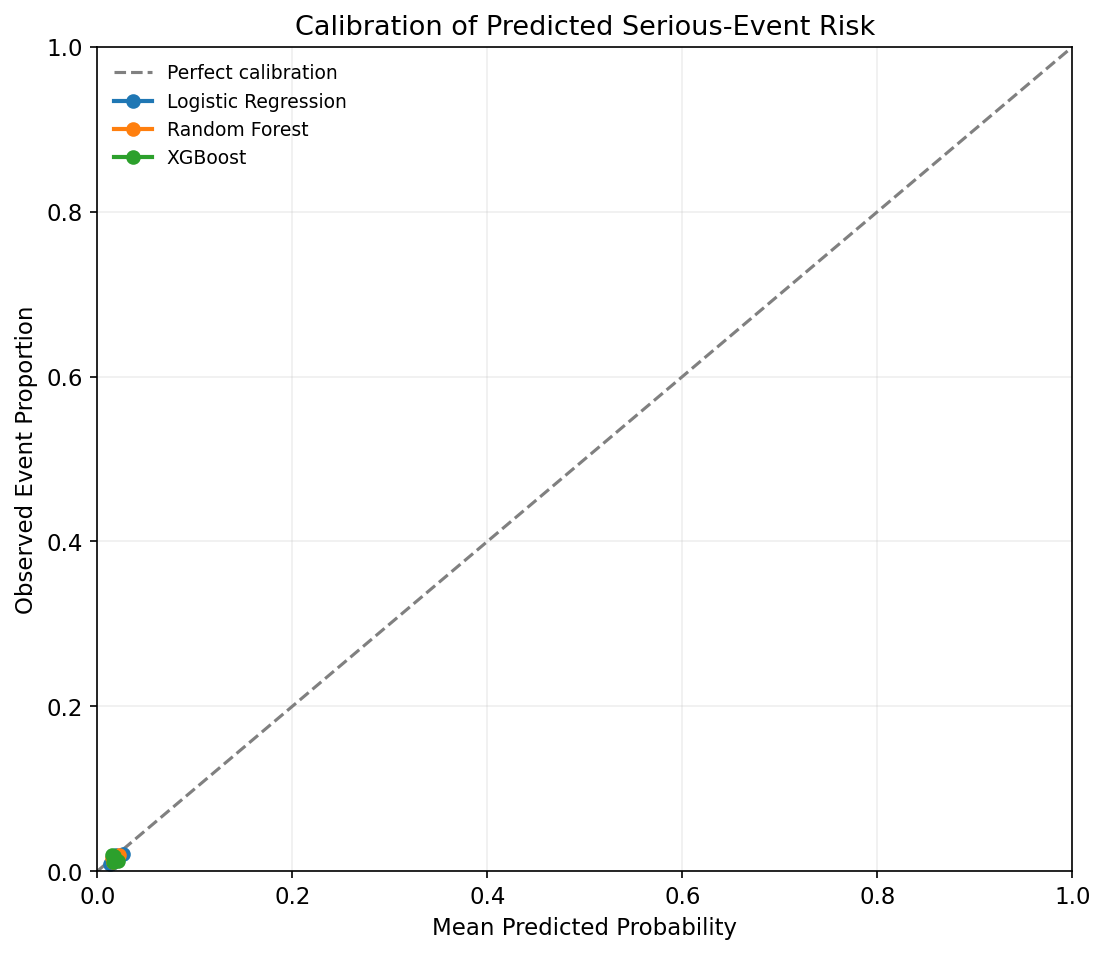


Saved calibration results, figure and predictions.


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import (
    CalibratedClassifierCV,
    calibration_curve
)

from sklearn.metrics import (
    brier_score_loss,
    log_loss,
    roc_auc_score,
    average_precision_score
)

from scipy.optimize import minimize
from scipy.special import expit

calibration_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

calibration_splits = list(
    calibration_cv.split(
        X_train,
        y_train,
        groups=groups_train
    )
)

for fold, (train_idx, val_idx) in enumerate(calibration_splits):

    train_patients = set(groups_train.iloc[train_idx])
    val_patients = set(groups_train.iloc[val_idx])

    assert len(train_patients.intersection(val_patients)) == 0

print("Patient-grouped calibration folds verified.")

calibrated_models = {}
calibrated_predictions = {}

for name in model_names:

    print(f"Calibrating {name}...")

    calibrator = CalibratedClassifierCV(
        estimator=models[name],
        method="sigmoid",
        cv=calibration_splits
    )

    calibrator.fit(X_train, y_train)

    calibrated_models[name] = calibrator

    calibrated_predictions[name] = (
        calibrator.predict_proba(X_test)[:, 1]
    )

def calculate_calibration_statistics(y, probabilities):

    y = np.asarray(y)
    p = np.clip(
        np.asarray(probabilities),
        1e-8,
        1 - 1e-8
    )

    logit_p = np.log(p / (1 - p))

    
    def intercept_loss(intercept):
        predicted = expit(logit_p + intercept[0])
        return -np.sum(
            y * np.log(predicted + 1e-12)
            + (1 - y) * np.log(1 - predicted + 1e-12)
        )

    intercept_fit = minimize(
        intercept_loss,
        x0=[0.0],
        method="BFGS"
    )

    calibration_in_large = intercept_fit.x[0]

   
    def joint_loss(params):
        predicted = expit(
            params[0] + params[1] * logit_p
        )

        return -np.sum(
            y * np.log(predicted + 1e-12)
            + (1 - y) * np.log(1 - predicted + 1e-12)
        )

    joint_fit = minimize(
        joint_loss,
        x0=[0.0, 1.0],
        method="BFGS"
    )

    return (
        calibration_in_large,
        joint_fit.x[0],
        joint_fit.x[1]
    )

calibration_results = []

for name in model_names:

    for prediction_type, probabilities in [
        ("Original", predictions[name]),
        ("Calibrated", calibrated_predictions[name])
    ]:

        intercept, joint_intercept, slope = (
            calculate_calibration_statistics(
                y_test,
                probabilities
            )
        )

        calibration_results.append({
            "Model": name,
            "Probability type": prediction_type,
            "AUROC": roc_auc_score(
                y_test, probabilities
            ),
            "AUPRC": average_precision_score(
                y_test, probabilities
            ),
            "Brier score": brier_score_loss(
                y_test, probabilities
            ),
            "Log loss": log_loss(
                y_test, probabilities,
                labels=[0, 1]
            ),
            "Calibration-in-the-large": intercept,
            "Calibration intercept": joint_intercept,
            "Calibration slope": slope,
            "Mean predicted risk": np.mean(probabilities),
            "Observed prevalence": np.mean(y_test)
        })

calibration_results = pd.DataFrame(
    calibration_results
)

print("\nCALIBRATION PERFORMANCE")
print("=" * 100)

display(calibration_results.round(4))

calibration_results.to_csv(
    "Corrected_Model_Calibration_Results.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(7.5, 6.5))

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="grey",
    linewidth=1.5,
    label="Perfect calibration"
)

for name in model_names:

    fraction_positive, mean_predicted = calibration_curve(
        y_test,
        calibrated_predictions[name],
        n_bins=5,
        strategy="quantile"
    )

    ax.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        linewidth=2,
        markersize=6,
        label=name
    )

ax.set_title("Calibration of Predicted Serious-Event Risk")
ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Observed Event Proportion")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(loc="upper left", frameon=False)
ax.grid(alpha=0.2)

fig.tight_layout()

fig.savefig(
    "Figure_Model_Calibration.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    "Figure_Model_Calibration.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


calibrated_prediction_data = pd.DataFrame({
    "subject_id": groups_test.values,
    "actual_outcome": y_test.values,
    **calibrated_predictions
})

calibrated_prediction_data.to_csv(
    "Corrected_Calibrated_Model_Predictions.csv",
    index=False
)

print("\nSaved calibration results, figure and predictions.")


In [29]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


In [30]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

SHAP version: 0.51.0


In [31]:
primary_model = models["Logistic Regression"]

preprocessor_fitted = primary_model.named_steps["preprocessor"]
classifier_fitted = primary_model.named_steps["classifier"]

X_test_transformed = preprocessor_fitted.transform(X_test)

feature_names = preprocessor_fitted.get_feature_names_out()

X_test_transformed = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)


X_train_transformed = preprocessor_fitted.transform(X_train)

X_train_transformed = pd.DataFrame(
    X_train_transformed,
    columns=feature_names,
    index=X_train.index
)

background = X_train_transformed.sample(
    n=min(500, len(X_train_transformed)),
    random_state=42
)


explainer = shap.LinearExplainer(
    classifier_fitted,
    background
)

shap_values = explainer(
    X_test_transformed
)

print("SHAP calculation completed.")
print("Test observations:", X_test_transformed.shape[0])
print("Transformed features:", X_test_transformed.shape[1])

SHAP calculation completed.
Test observations: 3562
Transformed features: 9


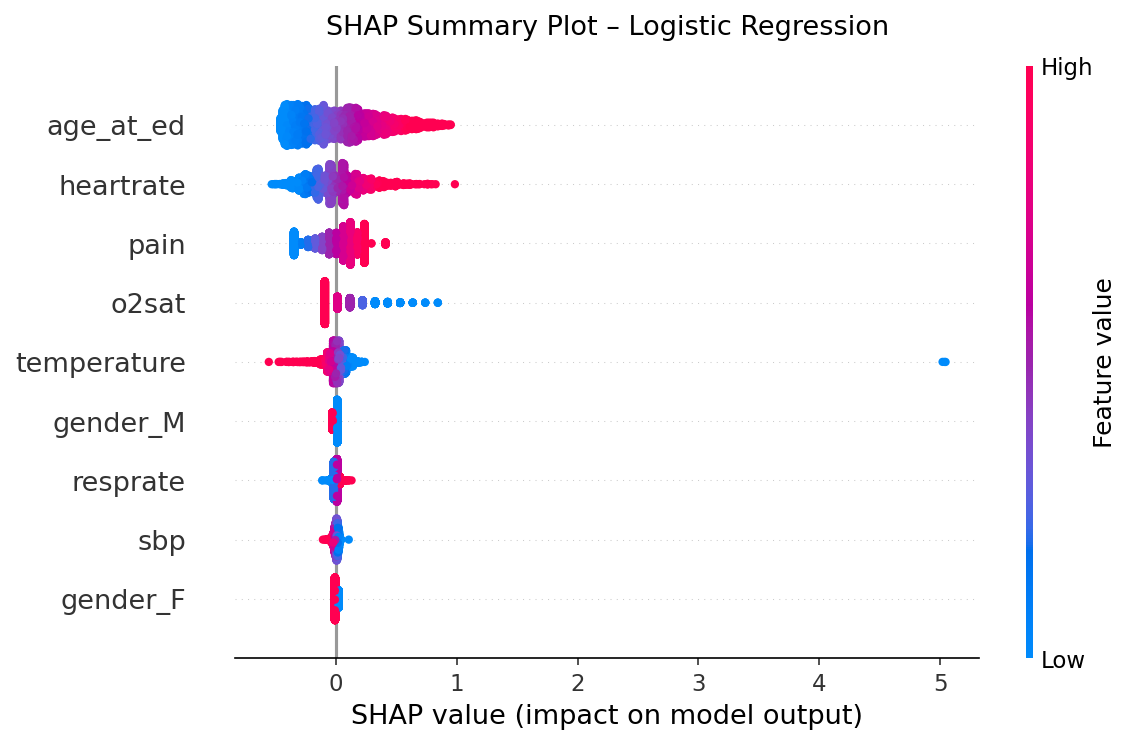

Updated SHAP figures saved with clean variable names.


In [33]:
clean_feature_names = [
    name.replace("numeric__", "")
        .replace("categorical__", "")
    for name in feature_names
]

shap_values_clean = shap.Explanation(
    values=shap_values.values,
    base_values=shap_values.base_values,
    data=shap_values.data,
    feature_names=clean_feature_names
)

plt.figure(figsize=(10, 7))

shap.plots.beeswarm(
    shap_values_clean,
    max_display=10,
    show=False
)

plt.title(
    "SHAP Summary Plot – Logistic Regression",
    pad=15
)

plt.tight_layout()

plt.savefig(
    "Figure_SHAP_Summary_Logistic_Regression.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_SHAP_Summary_Logistic_Regression.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Updated SHAP figures saved with clean variable names.")

In [34]:
shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean absolute SHAP value": np.abs(
        shap_values.values
    ).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean absolute SHAP value",
    ascending=False
).reset_index(drop=True)

print("SHAP FEATURE IMPORTANCE")
print("=" * 65)

display(shap_importance.round(5))

shap_importance.to_csv(
    "Table_SHAP_Feature_Importance.csv",
    index=False
)

print("Saved: Table_SHAP_Feature_Importance.csv")

SHAP FEATURE IMPORTANCE


,Feature,Mean absolute SHAP value
0,numeric__age_at_ed,0.27084
1,numeric__heartrate,0.16936
2,numeric__pain,0.15151
3,numeric__o2sat,0.11239
4,numeric__temperature,0.05622
5,categorical__gender_M,0.01557
6,numeric__resprate,0.01533
7,numeric__sbp,0.01424
8,categorical__gender_F,0.01190


Saved: Table_SHAP_Feature_Importance.csv


In [35]:
shap_matrix = pd.DataFrame(
    shap_values.values,
    columns=feature_names,
    index=X_test.index
)

gender_columns = [
    col for col in shap_matrix.columns
    if "gender_F" in col or "gender_M" in col
]

sex_shap = shap_matrix[gender_columns].sum(axis=1)

clinical_features = [
    "age_at_ed",
    "heartrate",
    "pain",
    "o2sat",
    "temperature",
    "resprate",
    "sbp"
]

combined_shap = pd.DataFrame(index=X_test.index)

for feature in clinical_features:
    matching_column = [
        col for col in shap_matrix.columns
        if col.endswith(feature)
    ][0]

    combined_shap[feature] = shap_matrix[matching_column]

combined_shap["sex"] = sex_shap

shap_importance_final = pd.DataFrame({
    "Feature": combined_shap.columns,
    "Mean absolute SHAP value": [
        np.abs(combined_shap[col]).mean()
        for col in combined_shap.columns
    ]
})

shap_importance_final = (
    shap_importance_final
    .sort_values("Mean absolute SHAP value", ascending=False)
    .reset_index(drop=True)
)

display(shap_importance_final.round(5))

shap_importance_final.to_csv(
    "Table_SHAP_Feature_Importance_Final.csv",
    index=False
)

print("Saved: Table_SHAP_Feature_Importance_Final.csv")

,Feature,Mean absolute SHAP value
0,age_at_ed,0.27084
1,heartrate,0.16936
2,pain,0.15151
3,o2sat,0.11239
4,temperature,0.05622
5,resprate,0.01533
6,sbp,0.01424
7,sex,0.00366


Saved: Table_SHAP_Feature_Importance_Final.csv


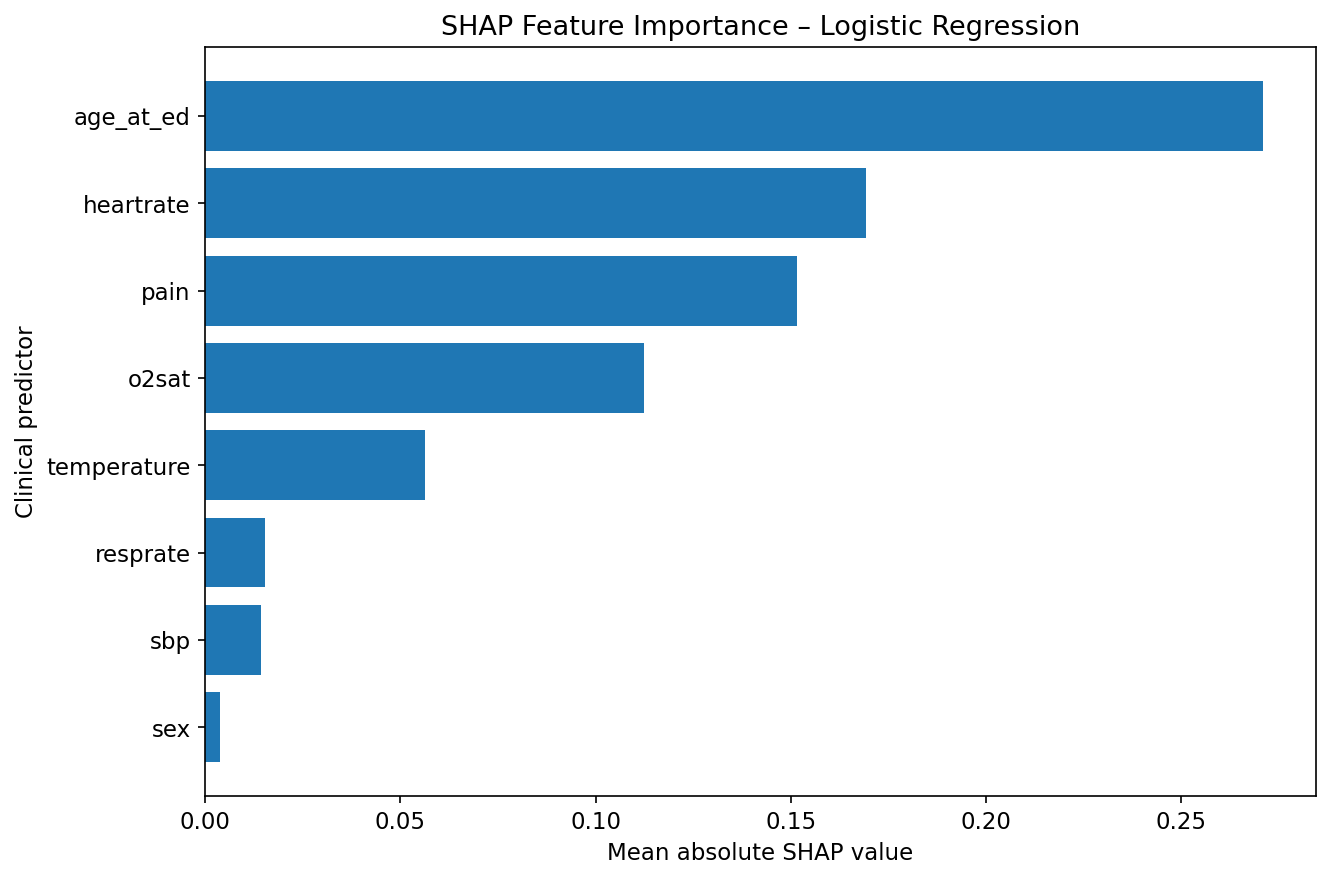

Final SHAP importance figures saved.


In [36]:
importance_plot = shap_importance_final.sort_values(
    "Mean absolute SHAP value",
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    importance_plot["Feature"],
    importance_plot["Mean absolute SHAP value"]
)

plt.xlabel("Mean absolute SHAP value")
plt.ylabel("Clinical predictor")

plt.title(
    "SHAP Feature Importance – Logistic Regression"
)

plt.tight_layout()

plt.savefig(
    "Figure_SHAP_Feature_Importance_Final.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_SHAP_Feature_Importance_Final.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Final SHAP importance figures saved.")

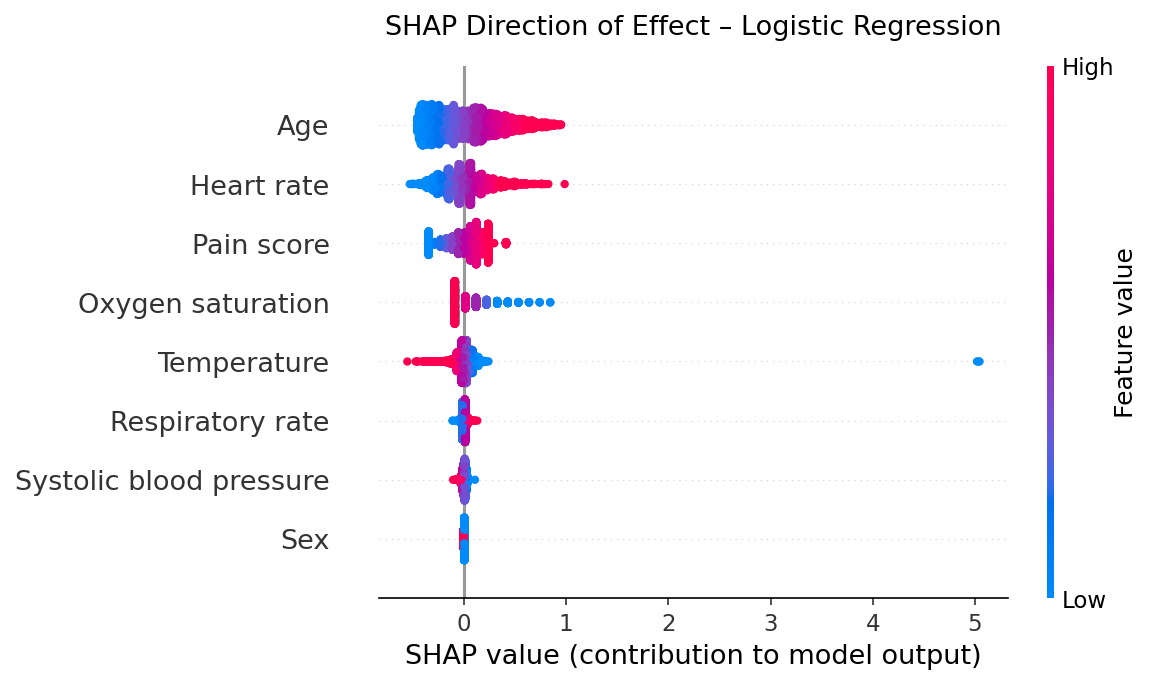

Saved final SHAP direction-of-effect figures.


In [37]:
shap_display_data = pd.DataFrame(index=X_test.index)

for feature in clinical_features:
    shap_display_data[feature] = pd.to_numeric(
        X_test[feature],
        errors="coerce"
    )

shap_display_data["sex"] = (
    X_test["gender"]
    .astype(str)
    .str.upper()
    .map({"F": 0, "M": 1})
)

shap_display_data = shap_display_data[
    combined_shap.columns
]

shap_direction = shap.Explanation(
    values=combined_shap.values,
    base_values=shap_values.base_values,
    data=shap_display_data.values,
    feature_names=[
        "Age",
        "Heart rate",
        "Pain score",
        "Oxygen saturation",
        "Temperature",
        "Respiratory rate",
        "Systolic blood pressure",
        "Sex"
    ]
)

plt.figure(figsize=(10, 7))

shap.plots.beeswarm(
    shap_direction,
    max_display=8,
    show=False
)

plt.title(
    "SHAP Direction of Effect – Logistic Regression",
    pad=15
)

plt.xlabel("SHAP value (contribution to model output)")

plt.tight_layout()

plt.savefig(
    "Figure_SHAP_Direction_of_Effect.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_SHAP_Direction_of_Effect.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Saved final SHAP direction-of-effect figures.")

In [38]:
from scipy.stats import spearmanr

direction_results = []

continuous_features = [
    "age_at_ed",
    "heartrate",
    "pain",
    "o2sat",
    "temperature",
    "resprate",
    "sbp"
]

for feature in continuous_features:

    rho, p_value = spearmanr(
        shap_display_data[feature],
        combined_shap[feature],
        nan_policy="omit"
    )

    direction_results.append({
        "Feature": feature,
        "Analysis": "Spearman correlation",
        "Direction": (
            "Higher values associated with higher model output"
            if rho > 0 else
            "Higher values associated with lower model output"
            if rho < 0 else
            "No monotonic relationship"
        ),
        "Correlation": rho,
        "P value": p_value
    })

for sex_value, sex_label in [(0, "Female"), (1, "Male")]:

    pass

sex_comparison = pd.DataFrame({
    "Sex": shap_display_data["sex"],
    "SHAP": combined_shap["sex"]
})

sex_means = sex_comparison.groupby("Sex")["SHAP"].mean()

female_mean = sex_means.get(0, np.nan)
male_mean = sex_means.get(1, np.nan)

direction_results.append({
    "Feature": "sex",
    "Analysis": "Mean SHAP contribution",
    "Direction": (
        "Male associated with higher model output"
        if male_mean > female_mean else
        "Female associated with higher model output"
        if female_mean > male_mean else
        "Similar mean contribution"
    ),
    "Correlation": np.nan,
    "P value": np.nan
})

direction_table = pd.DataFrame(direction_results)

print("SHAP DIRECTION-OF-EFFECT RESULTS")
print("=" * 75)

display(direction_table.round(4))

print("\nSEX-SPECIFIC MEAN SHAP CONTRIBUTIONS")
display(
    pd.DataFrame({
        "Sex": ["Female", "Male"],
        "Mean SHAP contribution": [female_mean, male_mean]
    }).round(5)
)

direction_table.to_csv(
    "Table_SHAP_Direction_of_Effect.csv",
    index=False
)

print("\nSaved: Table_SHAP_Direction_of_Effect.csv")

SHAP DIRECTION-OF-EFFECT RESULTS


,Feature,Analysis,Direction,Correlation,P value
0,age_at_ed,Spearman correlation,Higher values associated with higher model output,1.0,0.0
1,heartrate,Spearman correlation,Higher values associated with higher model output,1.0,1.0
2,pain,Spearman correlation,Higher values associated with higher model output,1.0,1.0
3,o2sat,Spearman correlation,Higher values associated with lower model output,-1.0,1.0
4,temperature,Spearman correlation,Higher values associated with lower model output,-1.0,0.0
5,resprate,Spearman correlation,Higher values associated with higher model output,1.0,1.0
6,sbp,Spearman correlation,Higher values associated with lower model output,-1.0,0.0
7,sex,Mean SHAP contribution,Female associated with higher model output,NaN,NaN



SEX-SPECIFIC MEAN SHAP CONTRIBUTIONS


,Sex,Mean SHAP contribution
0,Female,0.00245
1,Male,-0.00663



Saved: Table_SHAP_Direction_of_Effect.csv
